Logistic regression finds *a* line that separates the classes. When several lines all
achieve zero errors, nothing in its loss prefers one over another.

The support vector machine adds the missing criterion: **pick the line with the widest
margin**. Formally, maximise the distance to the nearest point of either class:

$$\max_{\mathbf{w},b} \; \frac{2}{\lVert\mathbf{w}\rVert}
\quad\text{subject to}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b) \ge 1$$

Two consequences follow, and both are visible in the numbers below:

1. Only the points **on** the margin matter. Everything else could be deleted without
   changing the answer &mdash; those few points are the *support vectors*.
2. The optimisation depends on the data only through **inner products**
   $\mathbf{x}_i^\top\mathbf{x}_j$. Replace that product with a kernel and the same
   algorithm draws curved boundaries in the original space without ever computing
   coordinates there.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs as the Logistic Regression and KNN walkthroughs.

Features are standardised throughout. For an SVM this is not cosmetic: the margin is
measured with a Euclidean norm, so unscaled features distort what "widest" means &mdash;
exactly the problem shown in the KNN notebook.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

labels recoded for SVM: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1  1]

The +/-1 convention is what makes the constraint y*(w.x + b) >= 1 work for
both classes with a single expression.



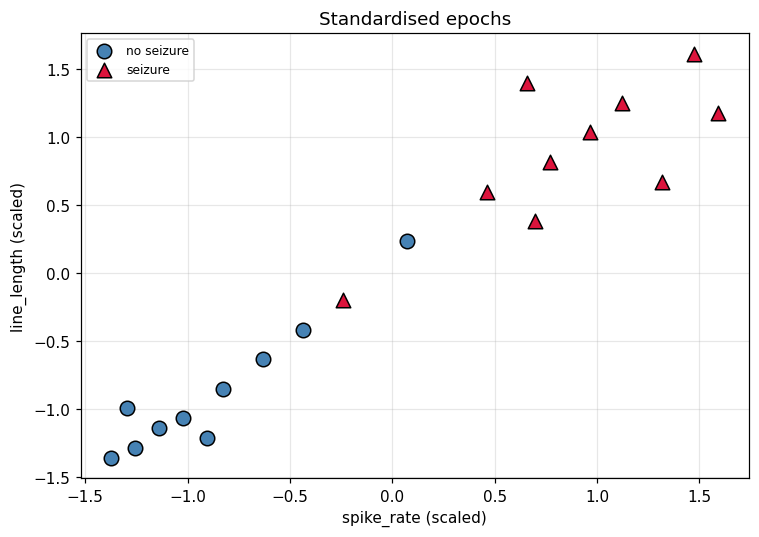

In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)
ypm = np.where(t2 == 1, 1, -1)          # SVMs use labels in {-1, +1}

print(f"labels recoded for SVM: {ypm}\n")
print("The +/-1 convention is what makes the constraint y*(w.x + b) >= 1 work for")
print("both classes with a single expression.\n")
plot2d(scaled=True, title="Standardised epochs")
plt.tight_layout(); plt.show()

---
# 2. The Line, and What $\mathbf{w}$ and $b$ Actually Mean

Before any optimisation, be precise about the object being optimised. A straight
boundary in two dimensions is written

$$w_1x_1 + w_2x_2 + b = 0 \qquad\text{or}\qquad \mathbf{w}^\top\mathbf{x} + b = 0$$

Two facts about this form do all the work later, and both are checkable:

**$\mathbf{w}$ is perpendicular to the line.** Take any two points
$\mathbf{p}, \mathbf{q}$ that lie *on* the line. Both satisfy the equation, so
subtracting gives $\mathbf{w}^\top(\mathbf{p} - \mathbf{q}) = 0$. The vector
$\mathbf{p}-\mathbf{q}$ points *along* the line, and its dot product with
$\mathbf{w}$ is zero — so $\mathbf{w}$ points straight across it. This is why
$\mathbf{w}$ is called the **normal vector**, and it is the reason every distance
on this page is measured in the direction of $\mathbf{w}$.

**The sign of $\mathbf{w}^\top\mathbf{x}+b$ says which side you are on.** Positive
on one side, negative on the other, exactly zero on the line. That single number
is called the **decision value**, and classification is nothing more than reading
its sign.

$b$ does not change the *direction* of the line, only how far it sits from the
origin. Changing $\mathbf{w}$ rotates the boundary; changing $b$ slides it.

In [4]:
# ---------------------------------------------------------------------------
#  Sections 2-7 use the same epochs, minus the two that were added on purpose
#  to make the data non-separable (ep09 and ep18). A *hard* margin only exists
#  if some line separates the classes at all; those two return in section 8.
# ---------------------------------------------------------------------------
keep   = np.array([i for i in range(n2) if i not in (9, 18)])
Xs     = Pz[keep]                     # standardised features
ys     = ypm[keep]                    # labels in {-1, +1}
ids_s  = [ep_ids[i] for i in keep]

banner("THE LINE, AND WHAT w AND b MEAN")
print(f"  using {len(keep)} of {n2} epochs (ep09 and ep18 held back until section 8)")
print(f"  class -1: {(ys==-1).sum()} epochs      class +1: {(ys==1).sum()} epochs")

# A hand-picked line, purely to inspect the geometry. Nothing is fitted yet.
w_demo = np.array([0.60, 0.80])
b_demo = -0.10

step("Fact 1: w is perpendicular to the line it defines")
print(f"  w = {w_demo},  b = {b_demo}")
print(f"  the line is  {w_demo[0]:.2f}*x1 + {w_demo[1]:.2f}*x2 + ({b_demo:.2f}) = 0")
print()

# Two points that lie exactly on the line: pick x1, solve for x2.
def on_line(x1, w_, b_):
    return np.array([x1, -(w_[0]*x1 + b_) / w_[1]])

p, q = on_line(-2.0, w_demo, b_demo), on_line(2.0, w_demo, b_demo)
print(f"  point p on the line = {np.round(p, 4)}   check w.p + b = "
      f"{w_demo @ p + b_demo:+.2e}")
print(f"  point q on the line = {np.round(q, 4)}   check w.q + b = "
      f"{w_demo @ q + b_demo:+.2e}")
along = p - q
print(f"\n  direction ALONG the line, p - q = {np.round(along, 4)}")
print(f"  w . (p - q) = ({w_demo[0]:.2f})({along[0]:+.4f}) + ({w_demo[1]:.2f})({along[1]:+.4f})"
      f" = {w_demo @ along:+.2e}")
print(f"  zero to floating point: {np.isclose(w_demo @ along, 0)}")
print(f"\n  A zero dot product means a 90 degree angle. So w is normal to the line,")
print(f"  and 'moving perpendicular to the boundary' means 'moving along w'.")

step("Fact 2: the sign of w.x + b is the side, and classification is reading it")
print(f"  {'epoch':>7}  {'x1':>8}  {'x2':>8}  {'w.x + b':>10}  {'sign':>6}  {'true y':>7}  ok")
print("  " + "-" * 62)
agree = 0
for j in range(0, len(Xs), 2):
    dv = float(w_demo @ Xs[j] + b_demo)
    sgn = 1 if dv > 0 else -1
    ok = sgn == ys[j]
    agree += ok
    print(f"  {ids_s[j]:>7}  {Xs[j,0]:>8.4f}  {Xs[j,1]:>8.4f}  {dv:>10.4f}"
          f"  {sgn:>+6}  {ys[j]:>+7}  {'yes' if ok else 'NO'}")
print("  " + "-" * 62)
allsgn = np.sign(Xs @ w_demo + b_demo)
print(f"  this hand-picked line classifies {int((allsgn == ys).sum())}/{len(ys)} correctly")
print(f"\n  Note what is NOT here: no notion yet of a good line versus a barely")
print(f"  adequate one. Any line with all signs correct scores the same. That gap")
print(f"  is what the margin fills.")

  THE LINE, AND WHAT w AND b MEAN
  using 18 of 20 epochs (ep09 and ep18 held back until section 8)
  class -1: 9 epochs      class +1: 9 epochs

Fact 1: w is perpendicular to the line it defines
  w = [0.6 0.8],  b = -0.1
  the line is  0.60*x1 + 0.80*x2 + (-0.10) = 0

  point p on the line = [-2.     1.625]   check w.p + b = +8.33e-17
  point q on the line = [ 2.    -1.375]   check w.q + b = +8.33e-17

  direction ALONG the line, p - q = [-4.  3.]
  w . (p - q) = (0.60)(-4.0000) + (0.80)(+3.0000) = +4.44e-16
  zero to floating point: True

  A zero dot product means a 90 degree angle. So w is normal to the line,
  and 'moving perpendicular to the boundary' means 'moving along w'.

Fact 2: the sign of w.x + b is the side, and classification is reading it
    epoch        x1        x2     w.x + b    sign   true y  ok
  --------------------------------------------------------------
     ep00   -1.2560   -1.2867     -1.8830      -1       -1  yes
     ep02   -1.3730   -1.3592     -2.0112 

---
# 3. Distance to a Line, and Why It Is Measured Perpendicular

The margin is a distance, so the distance has to be pinned down exactly.

For a point $\mathbf{x}_0$ the **perpendicular** distance to the boundary is

$$d(\mathbf{x}_0) = \frac{\lvert \mathbf{w}^\top\mathbf{x}_0 + b\rvert}{\lVert\mathbf{w}\rVert}$$

The numerator is the decision value from section 2. Dividing by
$\lVert\mathbf{w}\rVert$ converts it into an actual geometric length — without
that division you could double $\mathbf{w}$ and appear to double every distance
while the line has not moved at all.

**Why perpendicular?** Because *the shortest path from a point to a line is the
perpendicular one*. Any other route reaches the line at an angle and therefore
travels further. When we ask "how close is the nearest point to the boundary",
we mean the shortest distance, so we mean the perpendicular one.

The cell below does not assert this. It walks along the line, measures the
straight-line distance from a point to each spot, and shows the minimum falling
exactly on the perpendicular foot.

In [5]:
banner("DISTANCE TO A LINE, AND WHY PERPENDICULAR IS THE RIGHT ONE")

nw = np.linalg.norm(w_demo)
print(f"  w = {w_demo},  ||w|| = sqrt({w_demo[0]:.2f}^2 + {w_demo[1]:.2f}^2) = {nw:.6f}")

x0 = Xs[0]
step(f"Distance from epoch {ids_s[0]} at {np.round(x0, 4)}")
dv = float(w_demo @ x0 + b_demo)
print(f"  decision value  w.x0 + b = ({w_demo[0]:.2f})({x0[0]:+.4f}) + "
      f"({w_demo[1]:.2f})({x0[1]:+.4f}) + ({b_demo:.2f}) = {dv:+.6f}")
print(f"  distance        |{dv:+.6f}| / {nw:.6f} = {abs(dv)/nw:.6f}")

step("The perpendicular foot, computed explicitly")
# Step from x0 against the normal, by exactly the signed distance.
foot = x0 - (dv / nw**2) * w_demo
print(f"  move from x0 along -w by (w.x0+b)/||w||^2:")
print(f"    foot = x0 - ({dv:+.6f}/{nw**2:.6f}) * w = {np.round(foot, 6)}")
print(f"    is the foot on the line?  w.foot + b = {w_demo @ foot + b_demo:+.2e}"
      f"   -> {np.isclose(w_demo @ foot + b_demo, 0)}")
print(f"    ||x0 - foot|| = {np.linalg.norm(x0-foot):.6f}")
print(f"    formula gave  = {abs(dv)/nw:.6f}")
print(f"    MATCH: {np.isclose(np.linalg.norm(x0-foot), abs(dv)/nw)}")

step("Now walk along the line and measure. Is the perpendicular really shortest?")
ts = np.linspace(-2.5, 2.5, 21)
pts = np.array([on_line(t, w_demo, b_demo) for t in ts])
dists = np.linalg.norm(pts - x0, axis=1)
print(f"  {'point on line':>22}  {'distance to x0':>15}")
print("  " + "-" * 42)
for t, pt, d in list(zip(ts, pts, dists))[::2]:
    mark = "   <- shortest" if np.isclose(d, dists.min()) else ""
    print(f"  {str(np.round(pt, 3)):>22}  {d:>15.6f}{mark}")
print("  " + "-" * 42)
print(f"  minimum over the walk : {dists.min():.6f}")
print(f"  perpendicular formula : {abs(dv)/nw:.6f}")
print(f"  the closest sampled point is {np.linalg.norm(pts[dists.argmin()]-foot):.4f}")
print(f"  away from the exact foot, which is just the sampling step.")
print()
print(f"  So 'perpendicular' is not a convention someone chose. It is where the")
print(f"  distance function bottoms out.")

step("Signed distance: one number carrying both side and closeness")
print(f"  Dropping the absolute value keeps the sign, and multiplying by the")
print(f"  label y makes it positive exactly when the point is on its own side:")
print()
print(f"  {'epoch':>7}  {'y':>3}  {'w.x+b':>9}  {'signed dist':>12}  {'y * dist':>10}  meaning")
print("  " + "-" * 66)
for j in [0, 1, 8, 9, 15]:
    dvj = float(w_demo @ Xs[j] + b_demo)
    sd  = dvj / nw
    print(f"  {ids_s[j]:>7}  {ys[j]:>+3}  {dvj:>9.4f}  {sd:>12.4f}  {ys[j]*sd:>10.4f}"
          f"  {'correct side' if ys[j]*sd > 0 else 'WRONG side'}")
print("  " + "-" * 66)
print(f"  The quantity y*(w.x+b) is called the FUNCTIONAL MARGIN, and")
print(f"  y*(w.x+b)/||w|| the GEOMETRIC margin. Section 5 explains why the")
print(f"  algorithm optimises the first while we care about the second.")

  DISTANCE TO A LINE, AND WHY PERPENDICULAR IS THE RIGHT ONE
  w = [0.6 0.8],  ||w|| = sqrt(0.60^2 + 0.80^2) = 1.000000

Distance from epoch ep00 at [-1.256  -1.2867]
  decision value  w.x0 + b = (0.60)(-1.2560) + (0.80)(-1.2867) + (-0.10) = -1.882994
  distance        |-1.882994| / 1.000000 = 1.882994

The perpendicular foot, computed explicitly
  move from x0 along -w by (w.x0+b)/||w||^2:
    foot = x0 - (-1.882994/1.000000) * w = [-0.1262  0.2196]
    is the foot on the line?  w.foot + b = +1.80e-16   -> True
    ||x0 - foot|| = 1.882994
    formula gave  = 1.882994
    MATCH: True

Now walk along the line and measure. Is the perpendicular really shortest?
           point on line   distance to x0
  ------------------------------------------
             [-2.5  2. ]         3.514294
         [-2.     1.625]         3.005298
           [-1.5   1.25]         2.548456
         [-1.     0.875]         2.176852
             [-0.5  0.5]         1.940101
           [0.    0.125]         1.

---
# 4. Which Line Is Best? The max–min Rule

Now the actual question. Many lines classify every point correctly. Logistic
regression has no preference between them; the SVM does.

For each candidate line, look at **the nearest point to it** — the worst case —
and record that distance. Then choose the line whose worst case is the best:

$$\boxed{\;\max_{\mathbf{w},b}\;\Big[\;\min_i\; d(\mathbf{x}_i)\;\Big]\;}$$

Read it inside out: *first find the closest point, then pick the line that pushes
that closest point as far away as possible*. It is a max of a min, and the two
words are in that order for a reason — the goal is not the average distance, nor
the sum, but the **smallest** one.

Why the worst case rather than the average? Because a line can sit far from most
of the data and still shave past one point. That point is the one that will be
misclassified when a slightly different sample arrives. Optimising the average
would let the line trade safety on that point for distance from points that were
never at risk.

The table below does this literally: several separating lines, and for each one
the full list of distances collapsed to its minimum.

In [6]:
banner("COMPARING CANDIDATE LINES BY THEIR NEAREST POINT")

def geo_dists(w_, b_):
    """Perpendicular distance from every point to the line."""
    return np.abs(Xs @ w_ + b_) / np.linalg.norm(w_)

def separates(w_, b_):
    return bool((np.sign(Xs @ w_ + b_) == ys).all())

candidates = [
    ("A", np.array([ 0.80,  0.60]), -0.05),
    ("B", np.array([ 0.60,  0.80]), -0.10),
    ("C", np.array([ 1.00,  0.15]), -0.15),
    ("D", np.array([ 0.20,  1.00]), -0.05),
    ("E", np.array([ 0.72,  0.69]), -0.02),
]

step("Every candidate separates the data. That is not the question.")
print(f"  {'line':>5}  {'w':>16}  {'b':>7}  {'separates?':>11}  {'errors':>7}")
print("  " + "-" * 54)
for nm, w_, b_ in candidates:
    err = int((np.sign(Xs @ w_ + b_) != ys).sum())
    print(f"  {nm:>5}  {str(np.round(w_,2)):>16}  {b_:>7.2f}"
          f"  {str(separates(w_,b_)):>11}  {err:>7}")
print("  " + "-" * 54)
print("  All five score zero errors. A loss that only counts mistakes cannot")
print("  choose between them -- this is exactly the gap the margin fills.")

step("Line B in full: the distance from every single epoch")
w_, b_ = candidates[1][1], candidates[1][2]
d = geo_dists(w_, b_)
print(f"  {'epoch':>7}  {'y':>3}  {'distance':>10}")
print("  " + "-" * 26)
for j in np.argsort(d):
    mark = "   <- NEAREST" if j == d.argmin() else ""
    print(f"  {ids_s[j]:>7}  {ys[j]:>+3}  {d[j]:>10.4f}{mark}")
print("  " + "-" * 26)
print(f"  min over all {len(d)} epochs = {d.min():.6f}   (epoch {ids_s[d.argmin()]})")
print(f"  mean distance          = {d.mean():.6f}")
print(f"  Only the first number matters to an SVM.")

step("Collapse each candidate to its worst case, then rank")
print(f"  {'line':>5}  {'min distance':>13}  {'nearest epoch':>14}"
      f"  {'mean distance':>14}")
print("  " + "-" * 54)
rows = []
for nm, w_, b_ in candidates:
    dd = geo_dists(w_, b_)
    rows.append((nm, dd.min(), ids_s[dd.argmin()], dd.mean()))
    print(f"  {nm:>5}  {dd.min():>13.6f}  {ids_s[dd.argmin()]:>14}  {dd.mean():>14.6f}")
print("  " + "-" * 54)
best = max(rows, key=lambda r: r[1])
print(f"  max over the min column -> line {best[0]}, worst-case distance {best[1]:.6f}")
print()
bymean = max(rows, key=lambda r: r[3])
print(f"  Worth noticing: ranking by MEAN distance would pick line {bymean[0]}, "
      f"not {best[0]}.")
print(f"  The two criteria genuinely disagree, and the SVM takes the min.")

step("None of these five is optimal - they were guessed")
print("  The true optimum is not on this list. Section 4 only shows what is being")
print("  compared; sections 6 and 7 show how to actually find the best line,")
print("  first by formula and then by iteration.")

  COMPARING CANDIDATE LINES BY THEIR NEAREST POINT

Every candidate separates the data. That is not the question.
   line                 w        b   separates?   errors
  ------------------------------------------------------
      A         [0.8 0.6]    -0.05         True        0
      B         [0.6 0.8]    -0.10         True        0
      C       [1.   0.15]    -0.15         True        0
      D         [0.2 1. ]    -0.05         True        0
      E       [0.72 0.69]    -0.02         True        0
  ------------------------------------------------------
  All five score zero errors. A loss that only counts mistakes cannot
  choose between them -- this is exactly the gap the margin fills.

Line B in full: the distance from every single epoch
    epoch    y    distance
  --------------------------
     ep17   +1      0.6211   <- NEAREST
     ep12   +1      0.6546
     ep08   -1      0.6956
     ep05   -1      0.9866
     ep10   +1      1.0158
     ep16   +1      1.2275
     ep0

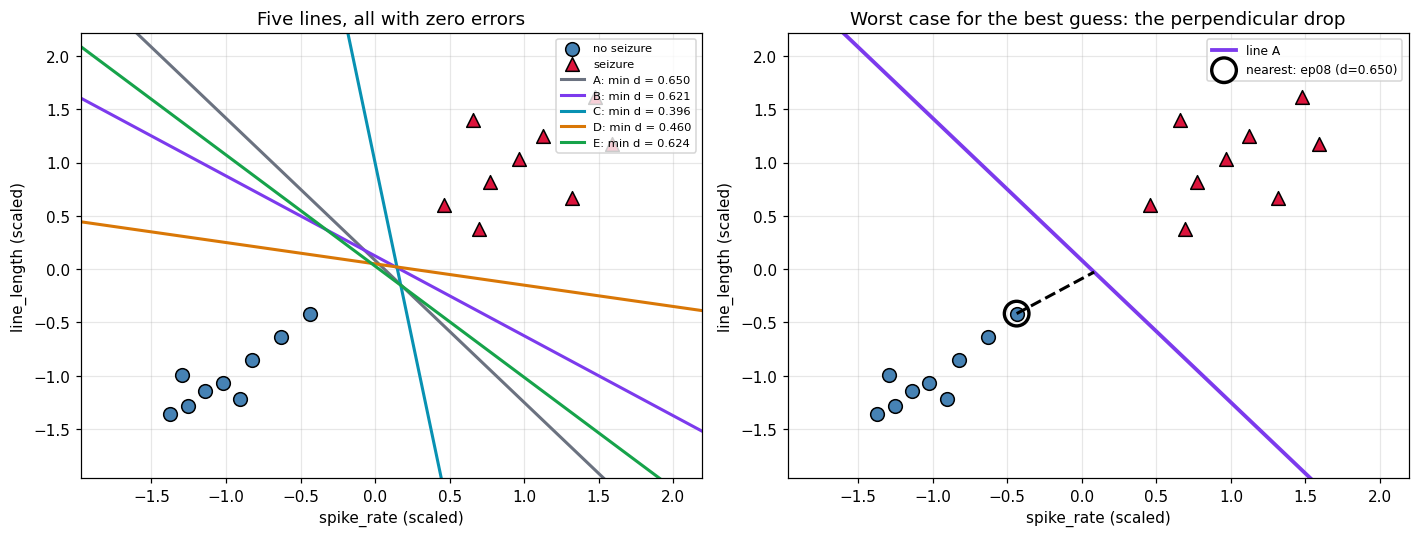

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

xs_line = np.linspace(Xs[:, 0].min() - 0.6, Xs[:, 0].max() + 0.6, 100)

ax = axes[0]
for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
    m = ys == (-1 if c == 0 else 1)
    ax.scatter(Xs[m, 0], Xs[m, 1], c=col, marker=mk, s=80, edgecolor="k", zorder=3,
               label=cls_names[c])
for (nm, w_, b_), col in zip(candidates, ["#6b7280", "#7c3aed", "#0891b2",
                                          "#d97706", "#16a34a"]):
    ax.plot(xs_line, -(w_[0]*xs_line + b_)/w_[1], lw=2, color=col,
            label=f"{nm}: min d = {geo_dists(w_,b_).min():.3f}")
ax.set(xlabel=feat2[0] + " (scaled)", ylabel=feat2[1] + " (scaled)",
       title="Five lines, all with zero errors")
ax.set_xlim(Xs[:,0].min()-0.6, Xs[:,0].max()+0.6)
ax.set_ylim(Xs[:,1].min()-0.6, Xs[:,1].max()+0.6)
ax.legend(fontsize=7.5); ax.grid(alpha=.3)

# right panel: the winning candidate with its nearest point marked
ax = axes[1]
nm, w_, b_ = [c for c in candidates if c[0] == best[0]][0]
d = geo_dists(w_, b_)
for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
    m = ys == (-1 if c == 0 else 1)
    ax.scatter(Xs[m, 0], Xs[m, 1], c=col, marker=mk, s=80, edgecolor="k", zorder=3)
ax.plot(xs_line, -(w_[0]*xs_line + b_)/w_[1], lw=2.5, color="#7c3aed",
        label=f"line {nm}")
# perpendicular segment from the nearest point to its foot
j = int(d.argmin())
dvj = float(w_ @ Xs[j] + b_)
footj = Xs[j] - (dvj/np.dot(w_, w_)) * w_
ax.plot([Xs[j,0], footj[0]], [Xs[j,1], footj[1]], "k--", lw=2, zorder=4)
ax.scatter(*Xs[j], s=260, facecolors="none", edgecolors="black", linewidths=2.2,
           zorder=5, label=f"nearest: {ids_s[j]} (d={d[j]:.3f})")
ax.set(xlabel=feat2[0] + " (scaled)", ylabel=feat2[1] + " (scaled)",
       title=f"Worst case for the best guess: the perpendicular drop")
ax.set_xlim(Xs[:,0].min()-0.6, Xs[:,0].max()+0.6)
ax.set_ylim(Xs[:,1].min()-0.6, Xs[:,1].max()+0.6)
ax.legend(fontsize=8); ax.grid(alpha=.3)

plt.tight_layout(); plt.show()

---
# 5. Three Parallel Lines, and the $\pm 1$ Convention

The max–min statement is correct but awkward to optimise, because
$(\mathbf{w}, b)$ is **not unique**: multiplying both by any positive constant
gives the identical line. Doubling $\mathbf{w}$ doubles every decision value
while moving nothing.

The SVM removes that freedom by *choosing* a scale. Require the nearest points to
produce a decision value of exactly $\pm 1$:

$$\mathbf{w}^\top\mathbf{x} + b = +1 \qquad \text{(upper margin line)}$$
$$\mathbf{w}^\top\mathbf{x} + b = \phantom{+}0 \qquad \text{(decision boundary)}$$
$$\mathbf{w}^\top\mathbf{x} + b = -1 \qquad \text{(lower margin line)}$$

All three are **parallel** — same $\mathbf{w}$, so the same normal direction, so
the same slope. They differ only in offset.

This costs nothing, because it is a choice of units rather than a restriction on
the line. What it buys is enormous: every point being on the correct side and
outside the margin becomes a single clean inequality covering both classes,

$$y_i(\mathbf{w}^\top\mathbf{x}_i + b) \ge 1$$

and the points achieving equality — sitting exactly on a margin line — are the
**support vectors**.

In [8]:
banner("RESCALING CHANGES THE NUMBERS, NOT THE LINE")

step("Same line, three different (w, b) pairs")
base_w, base_b = np.array([0.60, 0.80]), -0.10
print(f"  {'scale k':>8}  {'w':>18}  {'b':>8}  {'w.x0+b':>10}  {'distance':>10}")
print("  " + "-" * 60)
for k in [0.5, 1.0, 2.0, 5.0]:
    wk, bk = k*base_w, k*base_b
    dvk = float(wk @ Xs[0] + bk)
    print(f"  {k:>8.1f}  {str(np.round(wk,3)):>18}  {bk:>8.3f}  {dvk:>10.4f}"
          f"  {abs(dvk)/np.linalg.norm(wk):>10.6f}")
print("  " + "-" * 60)
print("  The decision value scales with k. The DISTANCE does not move at all,")
print("  because the ||w|| in the denominator scales with it too.")
print("  So (w, b) has one redundant degree of freedom, and we may spend it.")

step("Spend it: rescale so the nearest point sits at exactly |w.x+b| = 1")
w_, b_ = base_w.copy(), base_b
fm = ys * (Xs @ w_ + b_)                  # functional margins
k = 1.0 / fm.min()                        # rescale so the smallest becomes 1
w_s, b_s = k*w_, k*b_
print(f"  smallest functional margin before : {fm.min():.6f}")
print(f"  rescale by k = 1/{fm.min():.6f} = {k:.6f}")
fm_s = ys * (Xs @ w_s + b_s)
print(f"  smallest functional margin after  : {fm_s.min():.6f}")
print(f"  every point now satisfies y(w.x+b) >= 1 : {bool((fm_s >= 1-1e-9).all())}")

step("With the scale fixed, the three lines have concrete meaning")
print(f"  w = {np.round(w_s,4)},  b = {b_s:.4f},  ||w|| = {np.linalg.norm(w_s):.6f}")
print()
print(f"  {'line':>22}  {'equation':>26}  {'distance from boundary':>23}")
print("  " + "-" * 76)
nws = np.linalg.norm(w_s)
print(f"  {'upper margin':>22}  {'w.x + b = +1':>26}  {1/nws:>23.6f}")
print(f"  {'decision boundary':>22}  {'w.x + b =  0':>26}  {0.0:>23.6f}")
print(f"  {'lower margin':>22}  {'w.x + b = -1':>26}  {1/nws:>23.6f}")
print("  " + "-" * 76)
print(f"  total width between the margin lines = 2/||w|| = {2/nws:.6f}")

step("Who is a support vector? Whoever achieves equality")
print(f"  {'epoch':>7}  {'y':>3}  {'w.x+b':>9}  {'y(w.x+b)':>10}  status")
print("  " + "-" * 52)
for j in np.argsort(fm_s):
    tag = "SUPPORT VECTOR (on the margin)" if fm_s[j] < 1 + 1e-6 else "outside the margin"
    print(f"  {ids_s[j]:>7}  {ys[j]:>+3}  {float(Xs[j]@w_s+b_s):>9.4f}"
          f"  {fm_s[j]:>10.4f}  {tag}")
print("  " + "-" * 52)
sv = np.where(fm_s < 1 + 1e-6)[0]
print(f"  {len(sv)} support vector(s): {[ids_s[j] for j in sv]}")
print()
print(f"  This line was only rescaled, not optimised -- so it touches the margin")
print(f"  at whichever point happened to be nearest. After optimisation the")
print(f"  margin lines are pushed apart until they are pinned from BOTH sides.")

  RESCALING CHANGES THE NUMBERS, NOT THE LINE

Same line, three different (w, b) pairs
   scale k                   w         b      w.x0+b    distance
  ------------------------------------------------------------
       0.5           [0.3 0.4]    -0.050     -0.9415    1.882994
       1.0           [0.6 0.8]    -0.100     -1.8830    1.882994
       2.0           [1.2 1.6]    -0.200     -3.7660    1.882994
       5.0             [3. 4.]    -0.500     -9.4150    1.882994
  ------------------------------------------------------------
  The decision value scales with k. The DISTANCE does not move at all,
  because the ||w|| in the denominator scales with it too.
  So (w, b) has one redundant degree of freedom, and we may spend it.

Spend it: rescale so the nearest point sits at exactly |w.x+b| = 1
  smallest functional margin before : 0.621054
  rescale by k = 1/0.621054 = 1.610166
  smallest functional margin after  : 1.000000
  every point now satisfies y(w.x+b) >= 1 : True

With the sc

### Why $1$? And why $\pm 1$ is *not* a distance

Two questions people get stuck on here, and they have different answers.

**"Why 1 and not 5?"** No reason. Any positive constant works. Requiring the
nearest points to give $\pm 5$ describes exactly the same geometry — divide
$\mathbf{w}$ and $b$ by 5 and you are back to $\pm 1$. The 1 is chosen because
it makes the constraint read $y_i(\mathbf{w}^\top\mathbf{x}_i+b) \ge 1$ instead
of $\ge 5$. It is a choice of units, like measuring in metres rather than
centimetres.

**"What if the classes are only 0.5 apart? How can the margin be 1?"** This is
the real confusion, and the answer is that **it isn't**. The numbers $\pm 1$ are
values of the *decision function* $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x}+b$,
not lengths on the plot. The actual geometric gap is

$$\text{margin} = \frac{2}{\lVert\mathbf{w}\rVert}$$

and if the classes really are 0.5 apart, the optimiser produces
$\lVert\mathbf{w}\rVert = 4$, so $2/4 = 0.5$. The decision values stay at
$\pm 1$; $\lVert\mathbf{w}\rVert$ absorbs the geometry. Nothing is being
asserted about how far apart your classes are.

### A trap worth naming

It is tempting to conclude: *"minimising $\lVert\mathbf{w}\rVert$ widens the
margin, so take $\mathbf{w} = (4,2)$, halve it to $(1,0.5)$, and the margin
grows four-fold."*

**That is false, and the reason matters.** Scaling $\mathbf{w}$ and $b$ together
gives the *same line* — section 5 opened by showing exactly that. If the line has
not moved, no distance to it can have changed.

What goes wrong is that $2/\lVert\mathbf{w}\rVert$ is only the margin **when the
scale is fixed by the constraint**. Divorced from that, it is just a number.
The quantity that is genuinely scale-free is

$$\text{geometric margin} = \min_i \frac{y_i\,(\mathbf{w}^\top\mathbf{x}_i+b)}{\lVert\mathbf{w}\rVert}$$

and the cell below shows it staying stubbornly constant while
$2/\lVert\mathbf{w}\rVert$ swings by a factor of eight.

Minimising $\lVert\mathbf{w}\rVert$ only widens the margin **subject to
$y_i(\mathbf{w}^\top\mathbf{x}_i+b) \ge 1$**. Drop the constraint and the honest
answer is $\mathbf{w} = \mathbf{0}$, an infinite margin and no classifier at all.

In [9]:
banner("2/||w|| IS NOT THE MARGIN UNLESS THE SCALE IS PINNED")

w_ref_, b_ref_ = w_s.copy(), b_s          # the +/-1-normalised line from above

step("Rescale the SAME line and watch the two quantities disagree")
print(f"  {'k':>6}  {'||kw||':>9}  {'2/||kw||':>10}  {'min y*f(x)':>11}"
      f"  {'geometric margin':>17}")
print("  " + "-" * 62)
for k in [0.25, 0.5, 1.0, 2.0, 4.0]:
    wk, bk = k*w_ref_, k*b_ref_
    nk = np.linalg.norm(wk)
    fmk = ys * (Xs @ wk + bk)
    print(f"  {k:>6.2f}  {nk:>9.4f}  {2/nk:>10.4f}  {fmk.min():>11.4f}"
          f"  {fmk.min()/nk:>17.6f}")
print("  " + "-" * 62)
print(f"  Column 3 changes by a factor of {4/0.25:.0f} across these rows.")
print(f"  Column 5 does not move at all -- because the line did not move.")
print()
print(f"  Every row above is the SAME boundary. Check it: the predictions are")
same = all(bool((np.sign(Xs @ (k*w_ref_) + k*b_ref_) == np.sign(Xs @ w_ref_ + b_ref_)).all())
           for k in [0.25, 0.5, 2.0, 4.0])
print(f"  identical for every k -> {same}")

step("So the 'shrink w to widen the margin' shortcut is wrong")
w_a, b_a = np.array([4.0, 2.0]), -1.0
w_b, b_b = w_a/4, b_a/4                    # same direction, quarter the size
print(f"  line A: w = {w_a}, b = {b_a:.2f}   ||w|| = {np.linalg.norm(w_a):.4f}"
      f"   2/||w|| = {2/np.linalg.norm(w_a):.4f}")
print(f"  line B: w = {w_b}, b = {b_b:.2f}   ||w|| = {np.linalg.norm(w_b):.4f}"
      f"   2/||w|| = {2/np.linalg.norm(w_b):.4f}")
print()
print(f"  2/||w|| suggests line B has a {(2/np.linalg.norm(w_b))/(2/np.linalg.norm(w_a)):.0f}x wider margin. But:")
pa_ = on_line(0.0, w_a, b_a); qa_ = on_line(1.0, w_a, b_a)
print(f"    a point on line A: {np.round(pa_,4)}   on line B? "
      f"w_B.x + b_B = {w_b @ pa_ + b_b:+.2e}")
print(f"    a point on line A: {np.round(qa_,4)}   on line B? "
      f"w_B.x + b_B = {w_b @ qa_ + b_b:+.2e}")
print(f"    -> A and B are the SAME LINE. The margin cannot have changed.")
print()
ga = (ys*(Xs@w_a+b_a)).min()/np.linalg.norm(w_a)
gb = (ys*(Xs@w_b+b_b)).min()/np.linalg.norm(w_b)
print(f"  geometric margin of A = {ga:.6f}")
print(f"  geometric margin of B = {gb:.6f}")
print(f"  equal: {np.isclose(ga, gb)}")

step("What DOES change the margin: a different direction")
print(f"  Rotating w is the only way to move the boundary. Same points,")
print(f"  each direction normalised so the nearest point sits at exactly 1:")
print()
print(f"  {'direction w':>18}  {'||w|| after':>12}  {'true margin 2/||w||':>20}")
print("  " + "-" * 56)
# the last direction is the line joining the two class means -- a decent
# guess, and computable here without anything fitted yet
mean_dir = Xs[ys == 1].mean(0) - Xs[ys == -1].mean(0)
mean_dir = mean_dir / np.linalg.norm(mean_dir)
for wd in [np.array([1.0, 0.0]), np.array([0.7, 0.7]),
           np.array([0.6, 0.8]), mean_dir]:
    # pick the b that centres the two classes for this direction, then
    # rescale (w, b) so the closest point gives exactly 1
    proj = Xs @ wd
    bd = -(proj[ys == 1].min() + proj[ys == -1].max()) / 2
    fm_d = ys * (proj + bd)
    if fm_d.min() <= 0:
        print(f"  {str(np.round(wd,3)):>18}  {'--':>12}  {'does not separate':>20}")
        continue
    kd = 1.0 / fm_d.min()
    nd = np.linalg.norm(kd*wd)
    tag = "  <- joins the class means" if np.allclose(wd, mean_dir) else ""
    print(f"  {str(np.round(wd,3)):>18}  {nd:>12.4f}  {2/nd:>20.6f}{tag}")
print("  " + "-" * 56)
print(f"  These are genuinely different margins, because these are genuinely")
print(f"  different lines. That is the comparison section 4 was making, and")
print(f"  it is the one minimising ||w||^2 under the constraint carries out.")

  2/||w|| IS NOT THE MARGIN UNLESS THE SCALE IS PINNED

Rescale the SAME line and watch the two quantities disagree
       k     ||kw||    2/||kw||   min y*f(x)   geometric margin
  --------------------------------------------------------------
    0.25     0.4025      4.9684       0.2500           0.621054
    0.50     0.8051      2.4842       0.5000           0.621054
    1.00     1.6102      1.2421       1.0000           0.621054
    2.00     3.2203      0.6211       2.0000           0.621054
    4.00     6.4407      0.3105       4.0000           0.621054
  --------------------------------------------------------------
  Column 3 changes by a factor of 16 across these rows.
  Column 5 does not move at all -- because the line did not move.

  Every row above is the SAME boundary. Check it: the predictions are
  identical for every k -> True

So the 'shrink w to widen the margin' shortcut is wrong
  line A: w = [4. 2.], b = -1.00   ||w|| = 4.4721   2/||w|| = 0.4472
  line B: w = [1.  

---
# 6. Margin, and Why It Is $2/\lVert\mathbf{w}\rVert$

The boundary is $\mathbf{w}^\top\mathbf{x} + b = 0$. Fix the scale by requiring the
closest points of each class to satisfy $\mathbf{w}^\top\mathbf{x} + b = \pm 1$ &mdash; this
costs nothing, since $(\mathbf{w}, b)$ can always be rescaled.

The signed distance from a point to the hyperplane is

$$\text{distance} = \frac{\mathbf{w}^\top\mathbf{x} + b}{\lVert\mathbf{w}\rVert}$$

so the two margin planes sit at $\pm 1/\lVert\mathbf{w}\rVert$, and the gap between them is

$$\text{margin} = \frac{2}{\lVert\mathbf{w}\rVert}$$

**Maximising the margin is therefore minimising $\lVert\mathbf{w}\rVert$** &mdash; which is why
the SVM objective looks like a regularisation term with constraints attached.

In [10]:
from sklearn.svm import SVC

lin = SVC(kernel="linear", C=1.0).fit(Pz, t2)
w_sv = lin.coef_[0]
b_sv = float(lin.intercept_[0])

print(f"w = {np.round(w_sv, 6)}     b = {b_sv:+.6f}")
print(f"||w|| = sqrt({w_sv[0]:.4f}^2 + {w_sv[1]:.4f}^2) = {np.linalg.norm(w_sv):.6f}")
print(f"margin = 2 / ||w|| = 2 / {np.linalg.norm(w_sv):.6f} = "
      f"{2/np.linalg.norm(w_sv):.6f}\n")

f_x = Pz @ w_sv + b_sv
print(f"{'id':>6}  {'w.x + b':>10}  {'y':>4}  {'y(w.x+b)':>10}  {'dist to plane':>14}  {'status':>16}")
print("-" * 72)
for i in np.argsort(np.abs(f_x)):
    marg = ypm[i] * f_x[i]
    dist = f_x[i] / np.linalg.norm(w_sv)
    if marg < 0:
        st = "MISCLASSIFIED"
    elif marg <= 1 + 1e-6:
        st = "support vector"
    else:
        st = "safely outside"
    print(f"{ep_ids[i]:>6}  {f_x[i]:>10.5f}  {ypm[i]:>4}  {marg:>10.5f}  "
          f"{dist:>14.5f}  {st:>16}")
print("-" * 72)

print(f"\nsupport vectors found by sklearn: {[ep_ids[i] for i in lin.support_]}")
print(f"that is {len(lin.support_)} of {n2} points - the other "
      f"{n2 - len(lin.support_)} do not affect the solution at all.")

w = [0.8873 0.8112]     b = +0.075223
||w|| = sqrt(0.8873^2 + 0.8112^2) = 1.202211
margin = 2 / ||w|| = 2 / 1.202211 = 1.663602

    id     w.x + b     y    y(w.x+b)   dist to plane            status
------------------------------------------------------------------------
  ep18    -0.30107     1    -0.30107        -0.25043     MISCLASSIFIED
  ep09     0.32864    -1    -0.32864         0.27336     MISCLASSIFIED
  ep08    -0.65054    -1     0.65054        -0.54112    support vector
  ep12     0.96876     1     0.96876         0.80582    support vector
  ep17     1.00000     1     1.00000         0.83180    support vector
  ep05    -1.00000    -1     1.00000        -0.83180    support vector
  ep03    -1.34946    -1     1.34946        -1.12249    safely outside
  ep10     1.42205     1     1.42205         1.18287    safely outside
  ep01    -1.69893    -1     1.69893        -1.41317    safely outside
  ep07    -1.71271    -1     1.71271        -1.42464    safely outside
  ep14     1.7715

### Deleting the non-support vectors changes nothing

This is the claim worth testing directly: refit the SVM using **only** the support
vectors and the boundary should be identical.

In [11]:
sv_idx = lin.support_
lin_sv_only = SVC(kernel="linear", C=1.0).fit(Pz[sv_idx], t2[sv_idx])

print(f"trained on all {n2} points   : w = {np.round(lin.coef_[0], 6)}, "
      f"b = {lin.intercept_[0]:+.6f}")
print(f"trained on {len(sv_idx)} support vectors: w = {np.round(lin_sv_only.coef_[0], 6)}, "
      f"b = {lin_sv_only.intercept_[0]:+.6f}")
print(f"\nsame w? {np.allclose(lin.coef_[0], lin_sv_only.coef_[0], atol=1e-4)}")
print(f"same b? {np.isclose(lin.intercept_[0], lin_sv_only.intercept_[0], atol=1e-4)}")
print(f"same predictions on all {n2} points? "
      f"{np.array_equal(lin.predict(Pz), lin_sv_only.predict(Pz))}")

far = np.setdiff1d(np.arange(n2), sv_idx)
moved = Pz.copy()
moved[far] += np.sign(ypm[far])[:, None] * 2.0        # push them further away
lin_moved = SVC(kernel="linear", C=1.0).fit(moved, t2)
print(f"\nnow move every NON-support vector 2 units further from the boundary:")
print(f"   w before {np.round(lin.coef_[0], 5)}  ->  after {np.round(lin_moved.coef_[0], 5)}")
print(f"   unchanged? {np.allclose(lin.coef_[0], lin_moved.coef_[0], atol=1e-3)}")
print(f"\nThat is the defining property of an SVM: the solution is determined by a")
print(f"handful of boundary cases, not by the bulk of the data.")

trained on all 20 points   : w = [0.8873 0.8112], b = +0.075223
trained on 6 support vectors: w = [0.8873 0.8112], b = +0.075223

same w? True
same b? True
same predictions on all 20 points? True

now move every NON-support vector 2 units further from the boundary:
   w before [0.8873 0.8112]  ->  after [0.8873 0.8112]
   unchanged? True

That is the defining property of an SVM: the solution is determined by a
handful of boundary cases, not by the bulk of the data.


---
# 7. Watching the Boundary Being Learned

Section 6 gave the objective. This section watches it being solved, one update at
a time, because that is where the algorithm stops being a formula and starts
being something you can picture.

Production solvers use SMO or a quadratic programming routine. Those are
efficient and completely opaque. What follows instead is **subgradient descent on
the hinge loss**, which finds essentially the same boundary while letting every
single update be inspected:

$$J(\mathbf{w}, b) \;=\; \underbrace{\lambda\lVert\mathbf{w}\rVert^2}_{\text{widen the margin}} \;+\; \underbrace{\frac{1}{n}\sum_i \max\big(0,\; 1 - y_i(\mathbf{w}^\top\mathbf{x}_i + b)\big)}_{\text{punish anything inside the margin}}$$

The whole algorithm turns on one test, evaluated for each point:

$$y_i(\mathbf{w}^\top\mathbf{x}_i + b) \;\ge\; 1\;?$$

- **Satisfied** — the point is on the right side *and* outside the margin. It has no complaint. Only the regularisation term acts, shrinking $\mathbf{w}$, which *widens* the margin: $\mathbf{w} \leftarrow \mathbf{w} - \eta\,(2\lambda\mathbf{w})$
- **Violated** — the point is misclassified, or correct but sitting inside the margin. It pushes back: $\mathbf{w} \leftarrow \mathbf{w} - \eta\,(2\lambda\mathbf{w} - y_i\mathbf{x}_i)$ and $b \leftarrow b + \eta\, y_i$

Read the violated case geometrically. The term $+\eta\,y_i\mathbf{x}_i$ moves
$\mathbf{w}$ **toward** that point's own class direction, rotating the boundary
away from it; and the $b$ update slides the line in the same sense. The point
that complains is the point that moves the line.

Notice what this means: **a point outside the margin never rotates the boundary.**
Only violators do. That is the mechanism behind "only support vectors matter",
appearing here as a property of the update rule rather than as an assertion.

In [12]:
banner("THE DECISION TEST, EVALUATED BY HAND")

lam, eta = 0.01, 0.05
rng_svm = np.random.RandomState(0)
w_t = rng_svm.randn(2) * 0.5      # deliberately poor start
b_t = 0.0

print(f"  starting w = {np.round(w_t,4)},  b = {b_t:.4f}")
print(f"  learning rate eta = {eta},  regularisation lambda = {lam}")

step("What the test says about each epoch, before any update")
print(f"  {'epoch':>7}  {'y':>3}  {'w.x+b':>9}  {'y(w.x+b)':>10}  {'>= 1?':>6}  verdict")
print("  " + "-" * 68)
for j in range(len(Xs)):
    dv = float(w_t @ Xs[j] + b_t)
    fm = ys[j] * dv
    if fm >= 1:                       verdict = "content, outside the margin"
    elif fm > 0:                      verdict = "correct side, INSIDE the margin"
    else:                             verdict = "MISCLASSIFIED"
    print(f"  {ids_s[j]:>7}  {ys[j]:>+3}  {dv:>9.4f}  {fm:>10.4f}"
          f"  {str(fm >= 1):>6}  {verdict}")
print("  " + "-" * 68)
fm_all = ys * (Xs @ w_t + b_t)
print(f"  {int((fm_all >= 1).sum())} satisfied, {int((fm_all < 1).sum())} violating"
      f"  -> {int((fm_all < 1).sum())} points will push the line this epoch")

  THE DECISION TEST, EVALUATED BY HAND
  starting w = [0.882  0.2001],  b = 0.0000
  learning rate eta = 0.05,  regularisation lambda = 0.01

What the test says about each epoch, before any update
    epoch    y      w.x+b    y(w.x+b)   >= 1?  verdict
  --------------------------------------------------------------------
     ep00   -1    -1.3653      1.3653    True  content, outside the margin
     ep01   -1    -1.1153      1.1153    True  content, outside the margin
     ep02   -1    -1.4830      1.4830    True  content, outside the margin
     ep03   -1    -0.8998      0.8998   False  correct side, INSIDE the margin
     ep04   -1    -1.2330      1.2330    True  content, outside the margin
     ep05   -1    -0.6843      0.6843   False  correct side, INSIDE the margin
     ep06   -1    -1.3417      1.3417    True  content, outside the margin
     ep07   -1    -1.0411      1.0411    True  content, outside the margin
     ep08   -1    -0.4687      0.4687   False  correct side, INSIDE t

In [13]:
banner("THE FIRST FIVE UPDATES, WRITTEN OUT IN FULL")

w_t = rng_svm2 = np.random.RandomState(0).randn(2) * 0.5
b_t = 0.0
shown = 0
for j in range(len(Xs)):
    if shown >= 5:
        break
    dv = float(w_t @ Xs[j] + b_t)
    fm = ys[j] * dv
    ok = fm >= 1
    shown += 1
    print(f"\n  update {shown}: epoch {ids_s[j]}, x = {np.round(Xs[j],4)}, y = {ys[j]:+d}")
    print(f"    w.x + b   = ({w_t[0]:+.4f})({Xs[j,0]:+.4f}) + ({w_t[1]:+.4f})({Xs[j,1]:+.4f})"
          f" + ({b_t:+.4f}) = {dv:+.6f}")
    print(f"    y(w.x+b)  = ({ys[j]:+d})({dv:+.6f}) = {fm:+.6f}"
          f"   {'>= 1  SATISFIED' if ok else '<  1  VIOLATED'}")
    w_old, b_old = w_t.copy(), b_t
    if ok:
        w_t = w_t - eta * (2*lam*w_t)
        print(f"    rule: w <- w - eta*(2*lambda*w)          [only shrink w]")
    else:
        w_t = w_t - eta * (2*lam*w_t - ys[j]*Xs[j])
        b_t = b_t + eta * ys[j]
        print(f"    rule: w <- w - eta*(2*lambda*w - y*x)    [rotate toward this point]")
        print(f"          b <- b + eta*y")
    print(f"    w: {np.round(w_old,6)} -> {np.round(w_t,6)}"
          f"   (moved {np.linalg.norm(w_t-w_old):.6f})")
    print(f"    b: {b_old:+.6f} -> {b_t:+.6f}"
          f"   (moved {abs(b_t-b_old):.6f})")

print()
print("  Compare the two rules. A satisfied point changes w by a whisper and")
print("  leaves b untouched. A violated point drags both. Over an epoch, the")
print("  boundary is steered almost entirely by the points nearest to it.")

  THE FIRST FIVE UPDATES, WRITTEN OUT IN FULL

  update 1: epoch ep00, x = [-1.256  -1.2867], y = -1
    w.x + b   = (+0.8820)(-1.2560) + (+0.2001)(-1.2867) + (+0.0000) = -1.365269
    y(w.x+b)  = (-1)(-1.365269) = +1.365269   >= 1  SATISFIED
    rule: w <- w - eta*(2*lambda*w)          [only shrink w]
    w: [0.882  0.2001] -> [0.8811 0.1999]   (moved 0.000904)
    b: +0.000000 -> +0.000000   (moved 0.000000)

  update 2: epoch ep01, x = [-1.022  -1.0693], y = -1
    w.x + b   = (+0.8811)(-1.0220) + (+0.1999)(-1.0693) + (+0.0000) = -1.114215
    y(w.x+b)  = (-1)(-1.114215) = +1.114215   >= 1  SATISFIED
    rule: w <- w - eta*(2*lambda*w)          [only shrink w]
    w: [0.8811 0.1999] -> [0.8803 0.1997]   (moved 0.000904)
    b: +0.000000 -> +0.000000   (moved 0.000000)

  update 3: epoch ep02, x = [-1.373  -1.3592], y = -1
    w.x + b   = (+0.8803)(-1.3730) + (+0.1997)(-1.3592) + (+0.0000) = -1.480022
    y(w.x+b)  = (-1)(-1.480022) = +1.480022   >= 1  SATISFIED
    rule: w <- w - et

In [14]:
banner("TRAINING, WITH A SNAPSHOT AT EVERY CHECKPOINT")

def train_svm(X, y, epochs=800, eta=0.05, lam=0.01, seed=0, checkpoints=()):
    r = np.random.RandomState(seed)
    w, b = r.randn(X.shape[1]) * 0.5, 0.0
    snaps, hist = {}, []
    for ep in range(epochs + 1):
        fm = y * (X @ w + b)
        viol = int((fm < 1).sum())
        hinge = np.maximum(0, 1 - fm).mean()
        obj = lam * float(w @ w) + hinge
        hist.append((ep, w.copy(), b, viol, hinge, obj))
        if ep in checkpoints:
            snaps[ep] = (w.copy(), b, viol, obj)
        if ep == epochs:
            break
        for j in range(len(X)):                    # one pass over the data
            if y[j] * (X[j] @ w + b) >= 1:
                w = w - eta * (2*lam*w)
            else:
                w = w - eta * (2*lam*w - y[j]*X[j])
                b = b + eta * y[j]
    return w, b, snaps, hist

CHECK = (0, 1, 5, 20, 100, 800)
w_fin, b_fin, snaps, hist = train_svm(Xs, ys, epochs=800, eta=eta, lam=lam,
                                      seed=0, checkpoints=CHECK)

step("What changes from epoch to epoch")
print(f"  {'epoch':>6}  {'w1':>9}  {'w2':>9}  {'b':>9}  {'||w||':>8}"
      f"  {'margin 2/||w||':>15}  {'violators':>10}  {'objective':>10}")
print("  " + "-" * 88)
for ep, w_, b_, viol, hinge, obj in hist:
    if ep in CHECK:
        nw_ = np.linalg.norm(w_)
        print(f"  {ep:>6}  {w_[0]:>9.4f}  {w_[1]:>9.4f}  {b_:>9.4f}  {nw_:>8.4f}"
              f"  {2/nw_:>15.4f}  {viol:>10}  {obj:>10.4f}")
print("  " + "-" * 88)
print(f"  Read the margin column together with the violator column, because")
print(f"  2/||w|| is only a MARGIN once the constraints actually hold.")
print()
print(f"  Epoch 0 shows 2/||w|| = {2/np.linalg.norm(hist[0][1]):.4f}, the largest figure in the table --")
print(f"  and {hist[0][3]} points sitting between the margin lines. Wide lines with")
print(f"  points inside them are not a margin, they are a meaningless number.")
print()
print(f"  So the trajectory has two phases:")
m20  = 2/np.linalg.norm([h for h in hist if h[0]==20][0][1])
m100 = 2/np.linalg.norm([h for h in hist if h[0]==100][0][1])
print(f"    epochs 0-20   pushing points OUT of the margin. Doing that requires")
print(f"                  a bigger ||w||, so the nominal margin FALLS")
print(f"                  ({2/np.linalg.norm(hist[0][1]):.4f} -> {m20:.4f}) while the violator count drops"
      f" {hist[0][3]} -> {[h for h in hist if h[0]==20][0][3]}.")
print(f"    epochs 20+    constraints essentially met, so the figure now means")
print(f"                  what it says -- and regularisation widens it back")
print(f"                  ({m20:.4f} -> {m100:.4f}).")
print()
print(f"  The second phase is minimising ||w||^2 doing its job. The first phase")
print(f"  is the constraints being satisfied in the first place.")

step("Where the objective goes")
print(f"  {'epoch':>6}  {'reg term':>10}  {'hinge term':>12}  {'total':>10}")
print("  " + "-" * 44)
for ep, w_, b_, viol, hinge, obj in hist:
    if ep in CHECK:
        print(f"  {ep:>6}  {lam*float(w_@w_):>10.4f}  {hinge:>12.4f}  {obj:>10.4f}")
print("  " + "-" * 44)
h0 = hist[0]; h20 = [h for h in hist if h[0]==20][0]
print(f"  At epoch 0 the hinge term is {h0[4]:.4f} against a regularisation term of")
print(f"  {lam*float(h0[1]@h0[1]):.4f} -- it is {h0[4]/(lam*float(h0[1]@h0[1])):.0f}x larger, so essentially all of the")
print(f"  gradient is the misclassified points shouting.")
print()
print(f"  By epoch 20 the hinge term has collapsed to {h20[4]:.4f} and the two have")
print(f"  swapped places. From there the regularisation term is the only one")
print(f"  still doing anything, and what it does is shrink ||w||.")
print()
print(f"  This is why the total objective keeps falling after the last")
print(f"  misclassification is gone: the constraints are satisfied, and the")
print(f"  optimiser is still buying margin.")

step("Final state")
fm_fin = ys * (Xs @ w_fin + b_fin)
sv_fin = np.where(fm_fin < 1.05)[0]
print(f"  w = {np.round(w_fin,6)},  b = {b_fin:.6f}")
print(f"  ||w|| = {np.linalg.norm(w_fin):.6f}   margin = 2/||w|| = "
      f"{2/np.linalg.norm(w_fin):.6f}")
print(f"  all points satisfy y(w.x+b) >= 1 (to 1e-2): "
      f"{bool((fm_fin >= 1-1e-2).all())}")
print(f"  training errors: {int((np.sign(Xs@w_fin+b_fin) != ys).sum())}/{len(ys)}")
print()
print(f"  Note the table above ends with 1 'violator'. That is ep08 at")
print(f"  y(w.x+b) = {fm_fin[np.argmin(fm_fin)]:.4f} -- a support vector sitting a hair under 1.0,")
print(f"  not a misclassification. Training errors are {int((np.sign(Xs@w_fin+b_fin) != ys).sum())}. A strict")
print(f"  'y(w.x+b) < 1' test counts points that are exactly ON the margin.")
print()
print(f"  points closest to the margin ({len(sv_fin)}):")
for j in sv_fin:
    print(f"    {ids_s[j]:>7}  y = {ys[j]:+d}   y(w.x+b) = {fm_fin[j]:.4f}")

  TRAINING, WITH A SNAPSHOT AT EVERY CHECKPOINT

What changes from epoch to epoch
   epoch         w1         w2          b     ||w||   margin 2/||w||   violators   objective
  ----------------------------------------------------------------------------------------
       0     0.8820     0.2001     0.0000    0.9044           2.2113           7      0.1210
       1     1.0558     0.3797    -0.0000    1.1220           1.7826           4      0.0616
       5     1.2182     0.5972    -0.0000    1.3567           1.4741           2      0.0351
      20     1.2921     0.8629    -0.0500    1.5537           1.2872           1      0.0256
     100     1.0481     1.0430    -0.1000    1.4787           1.3526           1      0.0223
     800     0.9813     1.1103    -0.1000    1.4818           1.3497           1      0.0224
  ----------------------------------------------------------------------------------------
  Read the margin column together with the violator column, because
  2/||w|| is only

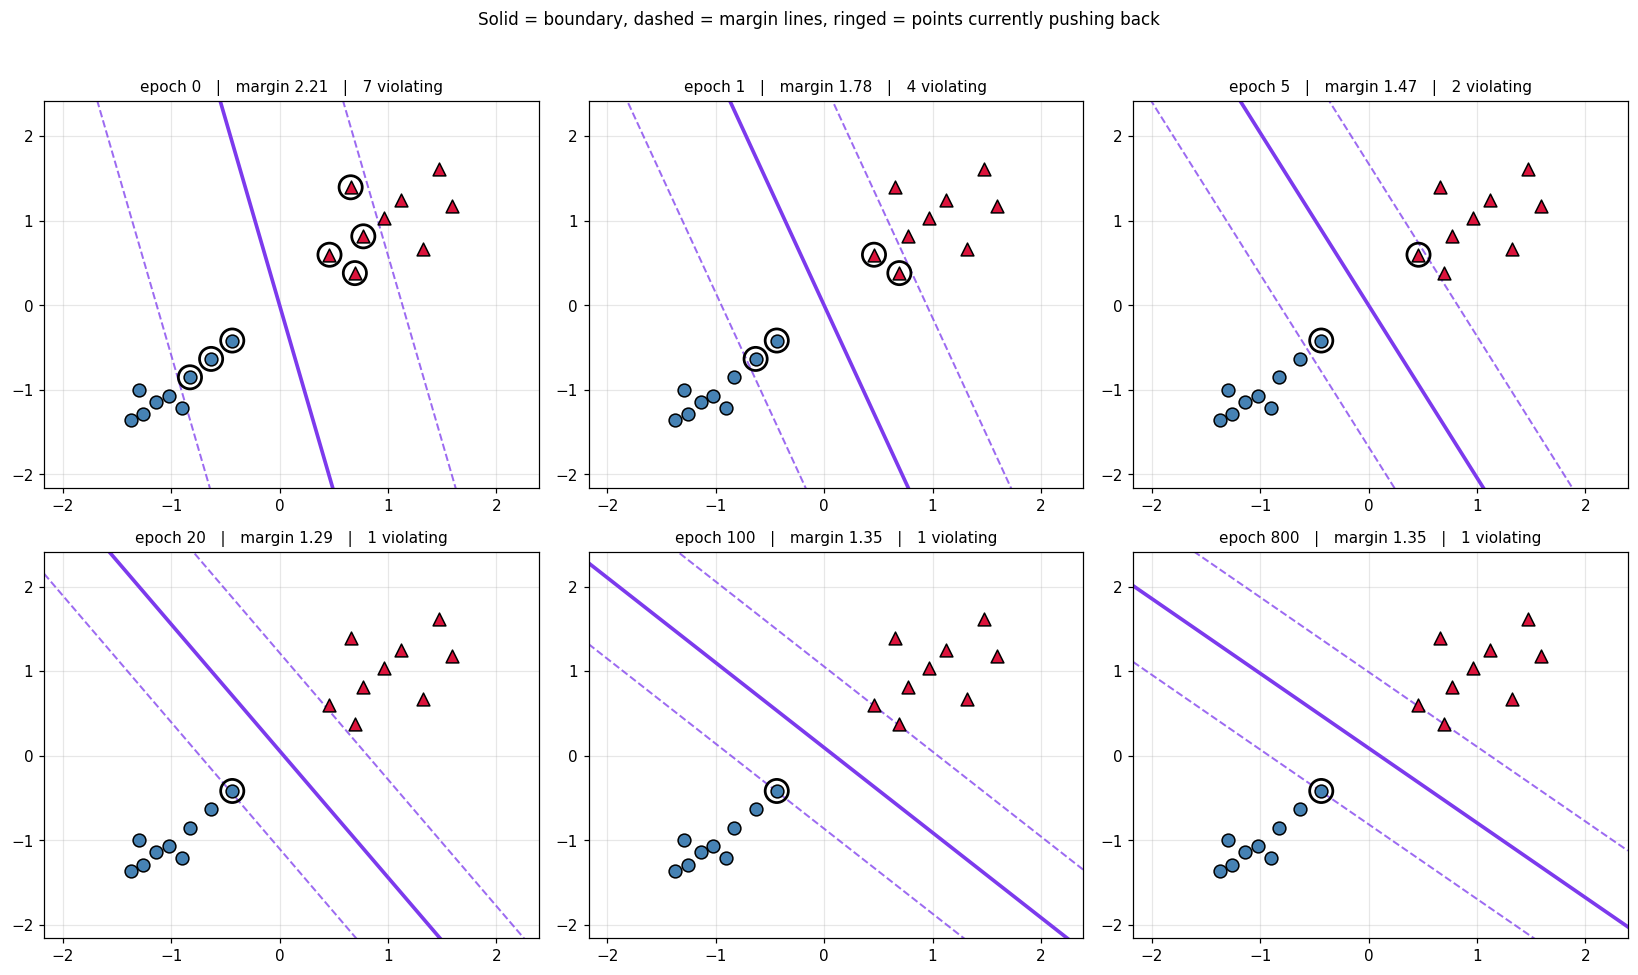

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
xs_line = np.linspace(Xs[:, 0].min() - 0.8, Xs[:, 0].max() + 0.8, 100)

for ax, ep in zip(axes.ravel(), CHECK):
    w_, b_, viol, obj = snaps[ep]
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = ys == (-1 if c == 0 else 1)
        ax.scatter(Xs[m, 0], Xs[m, 1], c=col, marker=mk, s=70, edgecolor="k",
                   zorder=3)
    if abs(w_[1]) > 1e-9:
        ax.plot(xs_line, -(w_[0]*xs_line + b_)/w_[1], lw=2.4, color="#7c3aed",
                zorder=2)
        ax.plot(xs_line, -(w_[0]*xs_line + b_ - 1)/w_[1], lw=1.3, ls="--",
                color="#7c3aed", alpha=.75, zorder=2)
        ax.plot(xs_line, -(w_[0]*xs_line + b_ + 1)/w_[1], lw=1.3, ls="--",
                color="#7c3aed", alpha=.75, zorder=2)
    # ring the points currently violating the margin: these are the ones
    # actually steering the boundary at this moment
    v = np.where(ys * (Xs @ w_ + b_) < 1)[0]
    if len(v):
        ax.scatter(Xs[v, 0], Xs[v, 1], s=230, facecolors="none",
                   edgecolors="black", linewidths=1.8, zorder=4)
    nw_ = np.linalg.norm(w_)
    ax.set_title(f"epoch {ep}   |   margin {2/nw_:.2f}   |   {viol} violating",
                 fontsize=10)
    ax.set_xlim(Xs[:,0].min()-0.8, Xs[:,0].max()+0.8)
    ax.set_ylim(Xs[:,1].min()-0.8, Xs[:,1].max()+0.8)
    ax.grid(alpha=.3)

fig.suptitle("Solid = boundary, dashed = margin lines, ringed = points currently "
             "pushing back", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

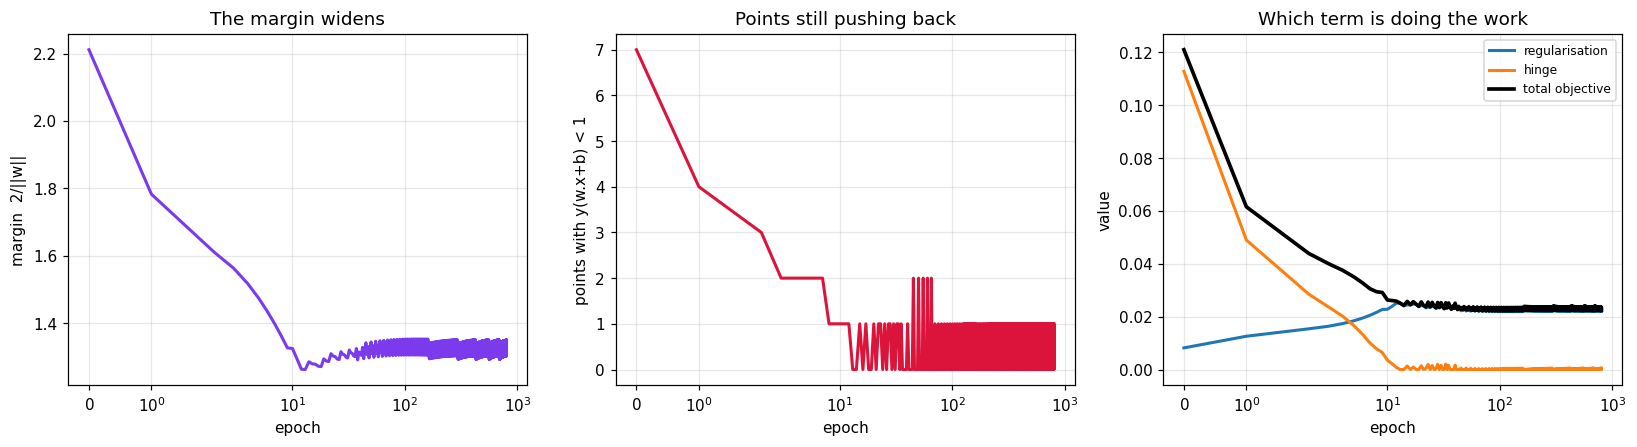

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
eps  = [h[0] for h in hist]

ax = axes[0]
ax.plot(eps, [2/np.linalg.norm(h[1]) for h in hist], lw=2, color="#7c3aed")
ax.set(xlabel="epoch", ylabel="margin  2/||w||", title="The margin widens")
ax.set_xscale("symlog"); ax.grid(alpha=.3)

ax = axes[1]
ax.plot(eps, [h[3] for h in hist], lw=2, color="crimson")
ax.set(xlabel="epoch", ylabel="points with y(w.x+b) < 1",
       title="Points still pushing back")
ax.set_xscale("symlog"); ax.grid(alpha=.3)

ax = axes[2]
ax.plot(eps, [lam*float(h[1]@h[1]) for h in hist], lw=2, label="regularisation")
ax.plot(eps, [h[4] for h in hist], lw=2, label="hinge")
ax.plot(eps, [h[5] for h in hist], lw=2.4, color="k", label="total objective")
ax.set(xlabel="epoch", ylabel="value", title="Which term is doing the work")
ax.set_xscale("symlog"); ax.legend(fontsize=8); ax.grid(alpha=.3)

plt.tight_layout(); plt.show()

### Does the hand-rolled loop agree with a real solver?

The loop above is a teaching device. If it lands somewhere different from a
proper QP solver, then watching it would teach the wrong thing — so the
comparison below is the point, not a formality.

The two will not match to machine precision, and should not be expected to:
subgradient descent with a fixed step size converges to a neighbourhood of the
optimum rather than onto it, and the $\lambda$ used here corresponds to a
particular $C$ in scikit-learn's parameterisation. What matters is that the
boundary lands in the same place and picks out the same support vectors.

In [17]:
banner("HAND-ROLLED SUBGRADIENT DESCENT vs A REAL QP SOLVER")

C_equiv = 1.0 / (2 * lam * len(Xs))
ref = SVC(kernel="linear", C=C_equiv).fit(Xs, ys)
w_ref, b_ref = ref.coef_[0], float(ref.intercept_[0])

step("Parameters")
print(f"  lambda = {lam} over n = {len(Xs)} points corresponds to C = "
      f"1/(2*lambda*n) = {C_equiv:.4f}")
print()
print(f"  {'':>16}  {'w1':>10}  {'w2':>10}  {'b':>10}  {'||w||':>9}  {'margin':>9}")
print("  " + "-" * 72)
print(f"  {'gradient descent':>16}  {w_fin[0]:>10.4f}  {w_fin[1]:>10.4f}"
      f"  {b_fin:>10.4f}  {np.linalg.norm(w_fin):>9.4f}"
      f"  {2/np.linalg.norm(w_fin):>9.4f}")
print(f"  {'sklearn SVC':>16}  {w_ref[0]:>10.4f}  {w_ref[1]:>10.4f}"
      f"  {b_ref:>10.4f}  {np.linalg.norm(w_ref):>9.4f}"
      f"  {2/np.linalg.norm(w_ref):>9.4f}")
print("  " + "-" * 72)

step("Do they describe the same line?")
cos = float(w_fin @ w_ref / (np.linalg.norm(w_fin)*np.linalg.norm(w_ref)))
ang = np.degrees(np.arccos(np.clip(cos, -1, 1)))
print(f"  angle between the two normal vectors = {ang:.3f} degrees")
print(f"  (0 would mean exactly parallel boundaries)")
print()
agree = int((np.sign(Xs@w_fin+b_fin) == np.sign(Xs@w_ref+b_ref)).sum())
print(f"  identical predictions on {agree}/{len(ys)} epochs")
print(f"  training errors -- ours: {int((np.sign(Xs@w_fin+b_fin)!=ys).sum())},"
      f"  sklearn: {int((ref.predict(Xs)!=ys).sum())}")

step("Do they choose the same support vectors?")
ours = set(np.where(ys*(Xs@w_fin+b_fin) < 1.05)[0].tolist())
theirs = set(ref.support_.tolist())
print(f"  ours    : {sorted(ids_s[j] for j in ours)}")
print(f"  sklearn : {sorted(ids_s[j] for j in theirs)}")
print(f"  overlap : {sorted(ids_s[j] for j in (ours & theirs))}")
print(f"  identical set: {ours == theirs}")
print()
print(f"  The boundary and the support vectors agree. The loop is a faithful,")
print(f"  slower picture of what the solver computes in one shot.")

  HAND-ROLLED SUBGRADIENT DESCENT vs A REAL QP SOLVER

Parameters
  lambda = 0.01 over n = 18 points corresponds to C = 1/(2*lambda*n) = 2.7778

                            w1          w2           b      ||w||     margin
  ------------------------------------------------------------------------
  gradient descent      0.9813      1.1103     -0.1000     1.4818     1.3497
       sklearn SVC      1.0055      1.0818     -0.1098     1.4769     1.3542
  ------------------------------------------------------------------------

Do they describe the same line?
  angle between the two normal vectors = 1.438 degrees
  (0 would mean exactly parallel boundaries)

  identical predictions on 18/18 epochs
  training errors -- ours: 0,  sklearn: 0

Do they choose the same support vectors?
  ours    : ['ep08', 'ep12', 'ep17']
  sklearn : ['ep08', 'ep12', 'ep17']
  overlap : ['ep08', 'ep12', 'ep17']
  identical set: True

  The boundary and the support vectors agree. The loop is a faithful,
  slower pic

### What to carry forward from section 7

- The **whole algorithm is one test**, $y_i(\mathbf{w}^\top\mathbf{x}_i+b) \ge 1$, applied point by point. Everything else is bookkeeping around it.
- A point that passes the test **contributes nothing but shrinkage**. It cannot rotate the boundary. This is "only support vectors matter", derived rather than asserted.
- The two terms take turns: the **hinge term** dominates early, dragging misclassified points to the right side; the **regularisation term** takes over once they are, quietly widening the margin.
- $2/\lVert\mathbf{w}\rVert$ is only a margin **once the constraints hold**. Early on it is at its largest precisely because points are still sitting inside it, so it has to *fall* before it can rise. Read it next to the violator count or it will mislead you.

One honest caveat: real SVM solvers do **not** work this way. SMO and quadratic
programming exploit the convexity of the problem to jump to the optimum instead
of walking to it, and they solve the dual form of section 9 rather than this one.
The picture above is faithful to the *objective*, not to the *method* — which is
exactly the trade worth making while learning what the objective means.

---
# 8. Soft Margin and $C$

Sections 2-7 held back epochs `ep09` and `ep18` so that a separating line
existed at all. **They come back now** &mdash; and the whole point of this section
is that the SVM no longer needs them to be separable.

Our data is not separable &mdash; two epochs sit on the wrong side. A hard margin has no
feasible solution at all, so slack variables $\xi_i \ge 0$ allow violations at a price:

$$\min_{\mathbf{w},b,\xi} \;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \xi_i
\qquad\text{s.t.}\qquad y_i(\mathbf{w}^\top\mathbf{x}_i+b) \ge 1 - \xi_i$$

Equivalently, in unconstrained form with the **hinge loss**:

$$\min_{\mathbf{w},b}\;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max\big(0,\; 1 - y_i(\mathbf{w}^\top\mathbf{x}_i + b)\big)$$

$C$ sets the exchange rate between margin width and violations:

* **small $C$** &mdash; violations are cheap, so the margin grows wide and more points sit inside it
* **large $C$** &mdash; violations are expensive, so the margin narrows to avoid them (approaching a hard margin)

In [18]:
def hinge_objective(w_, b_, Cv):
    marg = ypm * (Pz @ w_ + b_)
    hinge = np.maximum(0, 1 - marg)
    return 0.5*np.dot(w_, w_) + Cv*hinge.sum(), hinge

print(f"{'C':>8}  {'||w||':>9}  {'margin':>9}  {'#SV':>5}  {'sum slack':>10}  "
      f"{'train acc':>10}  {'objective':>11}")
print("-" * 72)
for Cv in (0.01, 0.1, 1.0, 10.0, 100.0, 1000.0):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    ww, bb = m.coef_[0], float(m.intercept_[0])
    obj, hinge = hinge_objective(ww, bb, Cv)
    print(f"{Cv:>8.2f}  {np.linalg.norm(ww):>9.4f}  {2/np.linalg.norm(ww):>9.4f}  "
          f"{len(m.support_):>5}  {hinge.sum():>10.4f}  {m.score(Pz, t2):>10.4f}  "
          f"{obj:>11.4f}")
print("-" * 72)
print("\nAs C grows the margin shrinks, the slack shrinks, and fewer points are")
print("support vectors. Small C is the more regularised model.")

print(f"\n\nhinge loss at C = 1, per point:\n")
m1 = SVC(kernel="linear", C=1.0).fit(Pz, t2)
_, hg = hinge_objective(m1.coef_[0], float(m1.intercept_[0]), 1.0)
print(f"{'id':>6}  {'y(w.x+b)':>10}  {'hinge':>9}  {'meaning':>28}")
print("-" * 60)
for i in np.argsort(-hg):
    marg = ypm[i]*(Pz[i] @ m1.coef_[0] + m1.intercept_[0])
    if hg[i] == 0:
        mean = "outside margin, no cost"
    elif marg > 0:
        mean = "inside margin, correct"
    else:
        mean = "on the wrong side"
    print(f"{ep_ids[i]:>6}  {marg:>10.5f}  {hg[i]:>9.5f}  {mean:>28}")
print("-" * 60)
print(f"\ntotal hinge = {hg.sum():.6f}")

       C      ||w||     margin    #SV   sum slack   train acc    objective
------------------------------------------------------------------------
    0.01     0.2482     8.0578     20     13.8393      0.9000       0.1692
    0.10     0.6917     2.8914     10      4.6859      0.9000       0.7078
    1.00     1.2022     1.6636      6      3.0104      0.9000       3.7331
   10.00     1.5731     1.2714      4      2.7568      0.9000      28.8058
  100.00     3.1708     0.6307      5      2.6343      0.9000     268.4573
 1000.00     3.1749     0.6299      5      2.6346      0.9000    2639.6695
------------------------------------------------------------------------

As C grows the margin shrinks, the slack shrinks, and fewer points are
support vectors. Small C is the more regularised model.


hinge loss at C = 1, per point:

    id    y(w.x+b)      hinge                       meaning
------------------------------------------------------------
  ep09    -0.32864    1.32864             on 

Gold circles are support vectors. Dashed lines are the margin boundaries.
Small C: wide margin, many support vectors, some violations tolerated.
Large C: narrow margin, few support vectors, violations avoided.


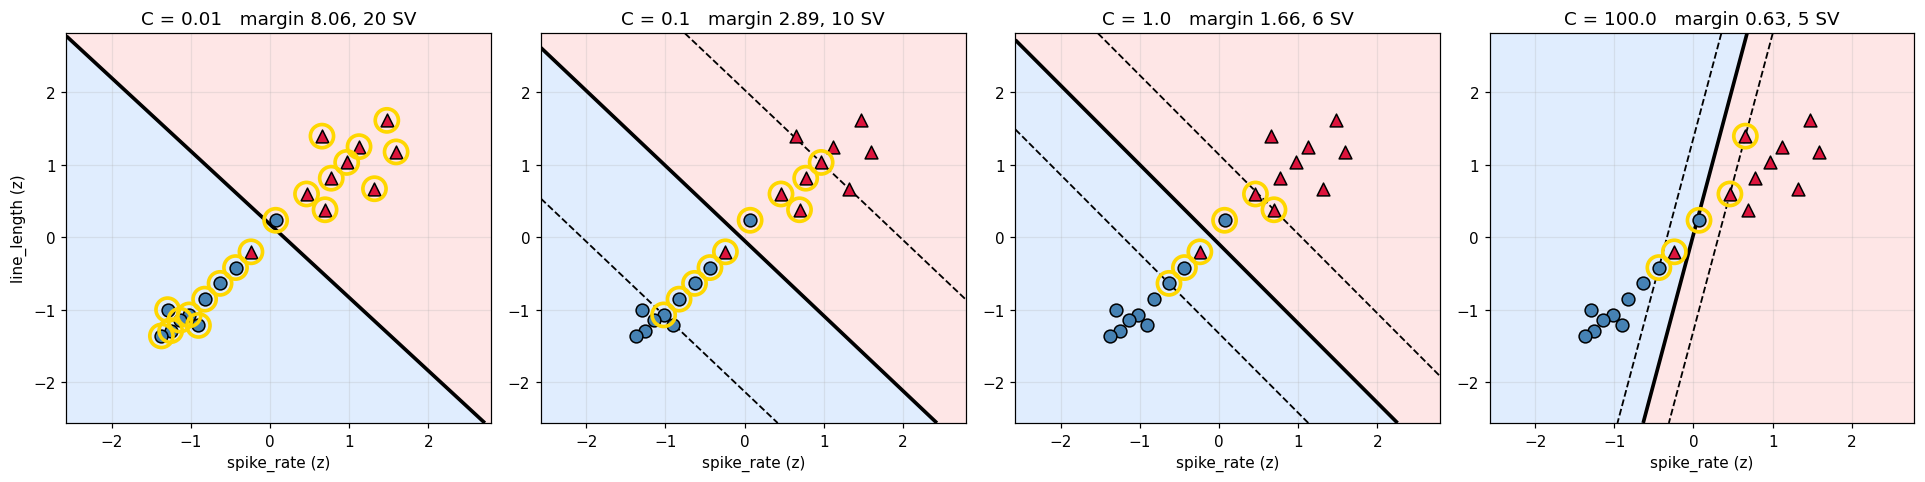

In [19]:
gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1.2, Pz[:,0].max()+1.2, 300),
                     np.linspace(Pz[:,1].min()-1.2, Pz[:,1].max()+1.2, 300))
G = np.column_stack([gx.ravel(), gy.ravel()])

Cs = [0.01, 0.1, 1.0, 100.0]
fig, axes = plt.subplots(1, len(Cs), figsize=(4.4*len(Cs), 4.5))
for ax, Cv in zip(axes, Cs):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    dec = m.decision_function(G).reshape(gx.shape)
    ax.contourf(gx, gy, dec > 0, levels=[-.5,.5,1.5], colors=["#dbeafe","#fee2e2"], alpha=.85)
    ax.contour(gx, gy, dec, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1.2, 2.4, 1.2])
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        mm = t2 == c
        ax.scatter(Pz[mm,0], Pz[mm,1], c=col, marker=mk, s=70, edgecolor="k", zorder=3)
    ax.scatter(Pz[m.support_,0], Pz[m.support_,1], s=230, facecolors="none",
               edgecolors="gold", linewidths=2.4, zorder=4)
    ax.set(title=f"C = {Cv}   margin {2/np.linalg.norm(m.coef_[0]):.2f}, "
                 f"{len(m.support_)} SV", xlabel=feat2[0]+" (z)")
    ax.grid(alpha=.25)
axes[0].set_ylabel(feat2[1]+" (z)")
plt.tight_layout(); plt.show()

print("Gold circles are support vectors. Dashed lines are the margin boundaries.")
print("Small C: wide margin, many support vectors, some violations tolerated.")
print("Large C: narrow margin, few support vectors, violations avoided.")

---
# 9. The Dual, and Where Kernels Come From

Introducing Lagrange multipliers $\alpha_i \ge 0$ for the constraints and eliminating
$\mathbf{w}$ and $b$ gives the **dual problem**:

$$\max_{\alpha} \;\; \sum_i \alpha_i - \frac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_i y_j \,\mathbf{x}_i^\top\mathbf{x}_j
\qquad\text{s.t.}\qquad 0 \le \alpha_i \le C, \;\; \sum_i \alpha_i y_i = 0$$

and the solution is recovered as

$$\mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$$

Two things are now visible that were hidden in the original form:

* **$\alpha_i = 0$ for every non-support vector.** The sum runs only over the few points
  on or inside the margin.
* **The data appears only as $\mathbf{x}_i^\top\mathbf{x}_j$.** Nothing else. Replace that
  inner product with any valid kernel $K(\mathbf{x}_i,\mathbf{x}_j)$ and the algorithm is
  unchanged &mdash; this is the *kernel trick*.

In [20]:
alpha_y = lin.dual_coef_[0]                 # sklearn stores alpha_i * y_i
alphas = np.abs(alpha_y)

print(f"sklearn returns {len(alpha_y)} dual coefficients (alpha_i * y_i):\n")
print(f"{'id':>6}  {'y':>4}  {'alpha*y':>11}  {'alpha':>10}  {'at bound C?':>12}")
print("-" * 50)
for k, i in enumerate(lin.support_):
    at_bound = "yes (C=1)" if np.isclose(alphas[k], 1.0, atol=1e-6) else "no"
    print(f"{ep_ids[i]:>6}  {ypm[i]:>4}  {alpha_y[k]:>11.6f}  {alphas[k]:>10.6f}  "
          f"{at_bound:>12}")
print("-" * 50)

print(f"\nconstraint check: sum of alpha_i * y_i = {alpha_y.sum():+.3e}   "
      f"(must be 0): {np.isclose(alpha_y.sum(), 0, atol=1e-6)}")

w_dual = (alpha_y[:, None] * Pz[lin.support_]).sum(axis=0)
print(f"\nrecovering w from the dual:  w = sum_i alpha_i y_i x_i\n")
for j, f in enumerate(feat2):
    terms = " + ".join(f"({alpha_y[k]:+.4f})*({Pz[i,j]:+.4f})"
                       for k, i in enumerate(lin.support_))
    print(f"   w[{j}] ({f}):")
    print(f"      {terms}")
    print(f"      = {w_dual[j]:+.6f}   |  sklearn: {w_sv[j]:+.6f}   "
          f"MATCH: {np.isclose(w_dual[j], w_sv[j])}")
print(f"\nfull w MATCH: {np.allclose(w_dual, w_sv)}")
print(f"\nEvery non-support vector has alpha = 0 and contributes nothing to this sum.")

sklearn returns 6 dual coefficients (alpha_i * y_i):

    id     y      alpha*y       alpha   at bound C?
--------------------------------------------------
  ep05    -1    -0.227861    0.227861            no
  ep08    -1    -1.000000    1.000000     yes (C=1)
  ep09    -1    -1.000000    1.000000     yes (C=1)
  ep12     1     1.000000    1.000000     yes (C=1)
  ep17     1     0.227861    0.227861            no
  ep18     1     1.000000    1.000000     yes (C=1)
--------------------------------------------------

constraint check: sum of alpha_i * y_i = +0.000e+00   (must be 0): True

recovering w from the dual:  w = sum_i alpha_i y_i x_i

   w[0] (spike_rate):
      (-0.2279)*(-0.6319) + (-1.0000)*(-0.4369) + (-1.0000)*(+0.0702) + (+1.0000)*(+0.4603) + (+0.2279)*(+0.6943) + (+1.0000)*(-0.2418)
      = +0.887281   |  sklearn: +0.887281   MATCH: True
   w[1] (line_length):
      (-0.2279)*(-0.6343) + (-1.0000)*(-0.4168) + (-1.0000)*(+0.2356) + (+1.0000)*(+0.5981) + (+0.2279)*(+0.3806)

---
# 10. Kernels

A kernel computes an inner product in some feature space $\phi$ **without ever building
$\phi(\mathbf{x})$**:

$$K(\mathbf{a},\mathbf{b}) = \phi(\mathbf{a})^\top\phi(\mathbf{b})$$

| Kernel | Formula | Feature space |
|---|---|---|
| Linear | $\mathbf{a}^\top\mathbf{b}$ | the original one |
| Polynomial | $(\gamma\,\mathbf{a}^\top\mathbf{b} + r)^d$ | all monomials up to degree $d$ |
| RBF / Gaussian | $\exp(-\gamma\lVert\mathbf{a}-\mathbf{b}\rVert^2)$ | **infinite-dimensional** |

The RBF case is the striking one: an infinite-dimensional feature map, evaluated in two
arithmetic operations. The explicit expansion below shows why the polynomial kernel works,
and by extension why the trick is legitimate.

In [21]:
a, b = Pz[0], Pz[10]
print(f"take two epochs:  a = {ep_ids[0]} = {np.round(a,4)}")
print(f"                  b = {ep_ids[10]} = {np.round(b,4)}\n")

print("POLYNOMIAL kernel, degree 2, gamma = 1, r = 1")
print("-" * 60)
k_poly = (a @ b + 1.0) ** 2
print(f"   K(a,b) = (a.b + 1)^2 = ({a @ b:.6f} + 1)^2 = {k_poly:.6f}")

def phi2(x):
    """The explicit feature map for (a.b + 1)^2 in 2-D."""
    x1, x2 = x
    return np.array([1.0, np.sqrt(2)*x1, np.sqrt(2)*x2,
                     x1**2, x2**2, np.sqrt(2)*x1*x2])

pa, pb = phi2(a), phi2(b)
print(f"\n   the explicit 6-dim map phi(x) = [1, sqrt2*x1, sqrt2*x2, x1^2, x2^2, sqrt2*x1*x2]")
print(f"   phi(a) = {np.round(pa, 5)}")
print(f"   phi(b) = {np.round(pb, 5)}")
print(f"\n   phi(a).phi(b) = {expand(pa, pb, per_line=3)}")
print(f"                 = {pa @ pb:.6f}")
print(f"   K(a,b)        = {k_poly:.6f}")
print(f"   MATCH: {np.isclose(pa @ pb, k_poly)}")
print(f"\n   The kernel computed in 2 operations what the explicit map needed 6")
print(f"   dimensions for. In degree 3 with 10 features the map has 286 terms;")
print(f"   the kernel is still one dot product and one power.\n")

print("RBF kernel, gamma = 0.5")
print("-" * 60)
gam = 0.5
d2 = np.sum((a-b)**2)
k_rbf = np.exp(-gam * d2)
print(f"   ||a - b||^2 = {expand(a-b, a-b, per_line=2)}")
print(f"               = {d2:.6f}")
print(f"   K(a,b) = exp(-{gam} * {d2:.6f}) = {k_rbf:.8f}")
print(f"\n   K depends ONLY on the distance, so it acts as a similarity that decays")
print(f"   with separation. K(x,x) = 1 always, and K -> 0 for distant points.")

take two epochs:  a = ep00 = [-1.256  -1.2867]
                  b = ep10 = [0.7723 0.8155]

POLYNOMIAL kernel, degree 2, gamma = 1, r = 1
------------------------------------------------------------
   K(a,b) = (a.b + 1)^2 = (-2.019426 + 1)^2 = 1.039229

   the explicit 6-dim map phi(x) = [1, sqrt2*x1, sqrt2*x2, x1^2, x2^2, sqrt2*x1*x2]
   phi(a) = [ 1.     -1.7762 -1.8197  1.5775  1.6557  2.2856]
   phi(b) = [1.     1.0922 1.1534 0.5965 0.6651 0.8908]

   phi(a).phi(b) = (+1.0000)*(+1.0000) + (-1.7762)*(+1.0922) + (-1.8197)*(+1.1534) + 
      (+1.5775)*(+0.5965) + (+1.6557)*(+0.6651) + (+2.2856)*(+0.8908)
                 = 1.039229
   K(a,b)        = 1.039229
   MATCH: True

   The kernel computed in 2 operations what the explicit map needed 6
   dimensions for. In degree 3 with 10 features the map has 286 terms;
   the kernel is still one dot product and one power.

RBF kernel, gamma = 0.5
------------------------------------------------------------
   ||a - b||^2 = (-2.0283)*(-2.0

In [22]:
def kernel_matrix(A, kind, gamma=0.5, degree=3, coef0=1.0):
    if kind == "linear":
        return A @ A.T
    if kind == "poly":
        return (gamma * (A @ A.T) + coef0) ** degree
    sq = np.sum(A**2, axis=1)
    return np.exp(-gamma * (sq[:, None] + sq[None, :] - 2 * A @ A.T))

Ksub = kernel_matrix(Pz, "rbf", gamma=0.5)[:6, :6]
show_matrix(Ksub, "RBF kernel matrix (first 6 epochs)", rows=ep_ids[:6],
            cols=ep_ids[:6], fmt="{:8.5f}")
print(f"\n   diagonal is all 1 (a point is maximally similar to itself): "
      f"{np.allclose(np.diag(kernel_matrix(Pz,'rbf')), 1.0)}")
print(f"   symmetric: {np.allclose(kernel_matrix(Pz,'rbf'), kernel_matrix(Pz,'rbf').T)}")
ev = np.linalg.eigvalsh(kernel_matrix(Pz, "rbf"))
print(f"   smallest eigenvalue = {ev.min():.3e}  -> positive semi-definite: "
      f"{ev.min() > -1e-8}")
print(f"\n   Positive semi-definiteness (Mercer's condition) is exactly what")
print(f"   guarantees some feature space phi exists for this kernel.")

RBF kernel matrix (first 6 epochs) (6, 6) =
                   ep00      ep01      ep02      ep03      ep04      ep05
         ep00 |  1.00000   0.95025   0.99057   0.82974   0.98279   0.66526
         ep01 |  0.95025   1.00000   0.90153   0.95823   0.99057   0.84310
         ep02 |  0.99057   0.90153   1.00000   0.75741   0.95025   0.58427
         ep03 |  0.82974   0.95823   0.75741   1.00000   0.91327   0.95823
         ep04 |  0.98279   0.99057   0.95025   0.91327   1.00000   0.77312
         ep05 |  0.66526   0.84310   0.58427   0.95823   0.77312   1.00000

   diagonal is all 1 (a point is maximally similar to itself): True
   symmetric: True
   smallest eigenvalue = 7.650e-08  -> positive semi-definite: True

   Positive semi-definiteness (Mercer's condition) is exactly what
   guarantees some feature space phi exists for this kernel.


                kernel   train acc    #SV
------------------------------------------
                linear      0.9000      6
                  poly      0.9500      4
         rbf gamma=0.5      0.9000      8
         rbf gamma=5.0      1.0000     16
------------------------------------------

gamma = 5 reaches 100% training accuracy by wrapping tight bubbles around
the two awkward epochs. That is memorisation, not generalisation - the
classic RBF failure mode when gamma is too large.


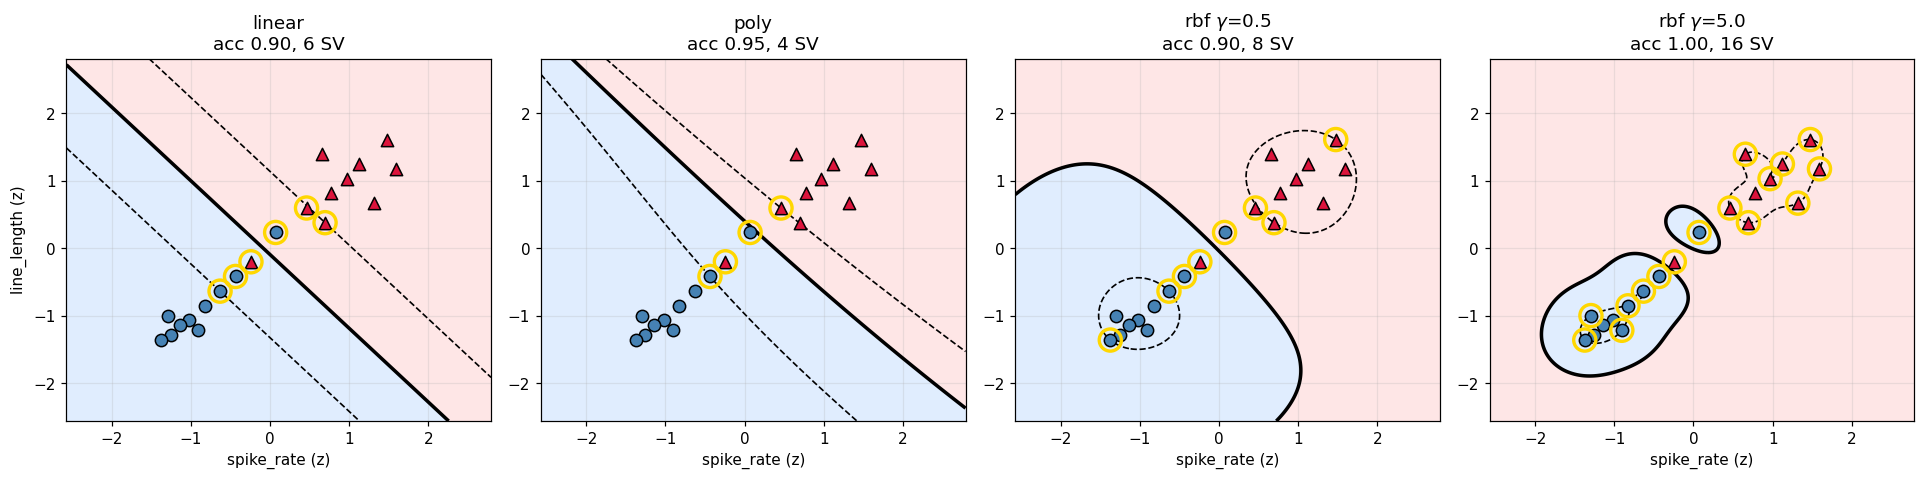

In [23]:
kernels = [("linear", {}), ("poly", dict(degree=3, gamma=1.0, coef0=1.0)),
           ("rbf", dict(gamma=0.5)), ("rbf", dict(gamma=5.0))]
fig, axes = plt.subplots(1, len(kernels), figsize=(4.4*len(kernels), 4.5))
for ax, (kn, kw) in zip(axes, kernels):
    m = SVC(kernel=kn, C=1.0, **kw).fit(Pz, t2)
    dec = m.decision_function(G).reshape(gx.shape)
    ax.contourf(gx, gy, dec > 0, levels=[-.5,.5,1.5], colors=["#dbeafe","#fee2e2"], alpha=.85)
    ax.contour(gx, gy, dec, levels=[-1,0,1], colors="k",
               linestyles=["--","-","--"], linewidths=[1.1,2.3,1.1])
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        mm = t2 == c
        ax.scatter(Pz[mm,0], Pz[mm,1], c=col, marker=mk, s=65, edgecolor="k", zorder=3)
    ax.scatter(Pz[m.support_,0], Pz[m.support_,1], s=210, facecolors="none",
               edgecolors="gold", linewidths=2.2, zorder=4)
    lab = kn + (f" $\\gamma$={kw['gamma']}" if kn=="rbf" else "")
    ax.set(title=f"{lab}\nacc {m.score(Pz,t2):.2f}, {len(m.support_)} SV",
           xlabel=feat2[0]+" (z)")
    ax.grid(alpha=.25)
axes[0].set_ylabel(feat2[1]+" (z)")
plt.tight_layout(); plt.show()

print(f"{'kernel':>22}  {'train acc':>10}  {'#SV':>5}")
print("-" * 42)
for kn, kw in kernels:
    m = SVC(kernel=kn, C=1.0, **kw).fit(Pz, t2)
    lab = kn + (f" gamma={kw['gamma']}" if kn=="rbf" else "")
    print(f"{lab:>22}  {m.score(Pz,t2):>10.4f}  {len(m.support_):>5}")
print("-" * 42)
print("\ngamma = 5 reaches 100% training accuracy by wrapping tight bubbles around")
print("the two awkward epochs. That is memorisation, not generalisation - the")
print("classic RBF failure mode when gamma is too large.")

### Seeing the lift: 2-D $\to$ 3-D on data no line can separate

The kernel table above is abstract. Here is the concrete picture behind it, on
the standard example: one class in a disc, the other in a ring around it.

**No straight line separates these.** Not a badly-chosen one — *none exists*. A
linear SVM still reaches about 72% by slicing off one side of the ring, so the
tell is not a score near chance; it is that the score cannot reach 100% however
hard you fit. Both classes share a centre, so every half-plane containing the
disc also swallows part of the ring.

Now add a third coordinate that measures distance from the centre:

$$\phi(x_1, x_2) = \big(x_1,\; x_2,\; x_1^2 + x_2^2\big)$$

Inner points get a small third coordinate, outer points a large one. In that
3-D space a **flat horizontal plane** $z = c$ separates them. Push the plane
back down to the plane it came from and $x_1^2 + x_2^2 = c$ is a **circle**.

That is the whole idea: *a curved boundary in the original space is a flat one
in a bigger space.* And the reason SVMs care is that everything in section 9
depended on the data only through inner products, so the algorithm never needs
$\phi$ itself — only $K(\mathbf{a},\mathbf{b}) = \phi(\mathbf{a})^\top\phi(\mathbf{b})$.

In [24]:
banner("A LINE CANNOT DO IT; A PLANE IN 3-D CAN")

rg = np.random.RandomState(7)
n_ring = 80
r_in  = rg.uniform(0.0, 1.0, n_ring)
r_out = rg.uniform(2.0, 3.0, n_ring)
th_in, th_out = rg.uniform(0, 2*np.pi, n_ring), rg.uniform(0, 2*np.pi, n_ring)

X_in  = np.c_[r_in*np.cos(th_in),   r_in*np.sin(th_in)]
X_out = np.c_[r_out*np.cos(th_out), r_out*np.sin(th_out)]
Xr = np.vstack([X_in, X_out])
yr = np.r_[-np.ones(n_ring), np.ones(n_ring)]

print(f"  {len(Xr)} points: {n_ring} in a disc of radius < 1,"
      f" {n_ring} in a ring of radius 2-3")

step("Try a straight line. Any straight line.")
lin_fail = SVC(kernel="linear", C=1e6).fit(Xr, yr)
acc_lin = float((lin_fail.predict(Xr) == yr).mean())
print(f"  linear SVM training accuracy = {acc_lin:.4f}")
print(f"  majority-class baseline      = {max((yr==1).mean(), (yr==-1).mean()):.4f}")
print(f"  errors that remain           = {int((lin_fail.predict(Xr)!=yr).sum())} of {len(yr)}")
print()
print(f"  Note the line is NOT at chance -- {acc_lin:.1%} beats the {0.5:.0%} baseline. It can")
print(f"  slice off one side of the ring and be right about that part. What it")
print(f"  cannot do is reach 1.0, and no amount of tuning C will change that:")
print(f"  the two classes share a centre,")
print(f"    mean of inner class = {np.round(Xr[yr==-1].mean(0), 4)}")
print(f"    mean of outer class = {np.round(Xr[yr==1].mean(0), 4)}")
print(f"  so every half-plane that contains the disc also contains a chunk of")
print(f"  the ring. The failure is structural, not a matter of fitting harder.")

step("Add the third coordinate  z = x1^2 + x2^2")
Z = (Xr ** 2).sum(axis=1)
X3 = np.c_[Xr, Z]
print(f"  {'class':>10}  {'z: min':>9}  {'z: max':>9}  {'z: mean':>9}")
print("  " + "-" * 42)
for lab, nm in [(-1, "inner disc"), (1, "outer ring")]:
    zz = Z[yr == lab]
    print(f"  {nm:>10}  {zz.min():>9.4f}  {zz.max():>9.4f}  {zz.mean():>9.4f}")
print("  " + "-" * 42)
gap_lo, gap_hi = Z[yr == -1].max(), Z[yr == 1].min()
print(f"  the two ranges do not overlap: {gap_lo:.4f} < {gap_hi:.4f}"
      f"  -> {gap_lo < gap_hi}")
print(f"  so ANY horizontal plane with {gap_lo:.3f} < c < {gap_hi:.3f} separates them.")

step("Fit a linear SVM in the lifted space")
lin3 = SVC(kernel="linear", C=1e6).fit(X3, yr)
w3, b3 = lin3.coef_[0], float(lin3.intercept_[0])
print(f"  accuracy after lifting = {float((lin3.predict(X3)==yr).mean()):.4f}")
print(f"  w = {np.round(w3,4)},  b = {b3:.4f}")
print()
print(f"  Look at the weights: w1 and w2 are ~{max(abs(w3[0]),abs(w3[1])):.3f}, w3 is"
      f" {w3[2]:.3f}.")
print(f"  The solver put essentially all the weight on the new coordinate and")
print(f"  ignored the originals -- it found the horizontal plane by itself.")

step("Push the plane back down: what is it in the original 2-D?")
print(f"  the plane is   w1*x1 + w2*x2 + w3*z + b = 0")
print(f"  substitute     z = x1^2 + x2^2:")
print(f"    {w3[0]:+.4f}*x1 {w3[1]:+.4f}*x2 {w3[2]:+.4f}*(x1^2 + x2^2) {b3:+.4f} = 0")
print()
c_eff = -b3 / w3[2]
print(f"  with w1, w2 near zero this is essentially  x1^2 + x2^2 = {c_eff:.4f}")
print(f"  a CIRCLE of radius sqrt({c_eff:.4f}) = {np.sqrt(c_eff):.4f}")
print(f"  which sits between the disc (max radius {np.sqrt(gap_lo):.4f}) and")
print(f"  the ring (min radius {np.sqrt(gap_hi):.4f}) -- exactly where it should.")

step("The same boundary without ever building phi: an RBF kernel")
rbf_ring = SVC(kernel="rbf", C=1.0, gamma=0.5).fit(Xr, yr)
print(f"  RBF SVM on the ORIGINAL 2-D data, accuracy ="
      f" {float((rbf_ring.predict(Xr)==yr).mean()):.4f}")
print(f"  support vectors: {rbf_ring.n_support_.sum()} of {len(Xr)}")
print()
print(f"  No z coordinate was ever computed. The kernel supplied the inner")
print(f"  products of a feature space we never constructed -- and for the RBF")
print(f"  kernel that space is infinite-dimensional, so we could not have")
print(f"  constructed it anyway. That is the trick, and it is why section 9")
print(f"  mattered: the dual only ever asked for inner products.")

  A LINE CANNOT DO IT; A PLANE IN 3-D CAN
  160 points: 80 in a disc of radius < 1, 80 in a ring of radius 2-3

Try a straight line. Any straight line.
  linear SVM training accuracy = 0.7188
  majority-class baseline      = 0.5000
  errors that remain           = 45 of 160

  Note the line is NOT at chance -- 71.9% beats the 50% baseline. It can
  slice off one side of the ring and be right about that part. What it
  cannot do is reach 1.0, and no amount of tuning C will change that:
  the two classes share a centre,
    mean of inner class = [-0.0059  0.0158]
    mean of outer class = [0.3631 0.0525]
  so every half-plane that contains the disc also contains a chunk of
  the ring. The failure is structural, not a matter of fitting harder.

Add the third coordinate  z = x1^2 + x2^2
       class     z: min     z: max    z: mean
  ------------------------------------------
  inner disc     0.0000     0.9565     0.3184
  outer ring     4.0286     8.9554     6.3182
  ---------------------

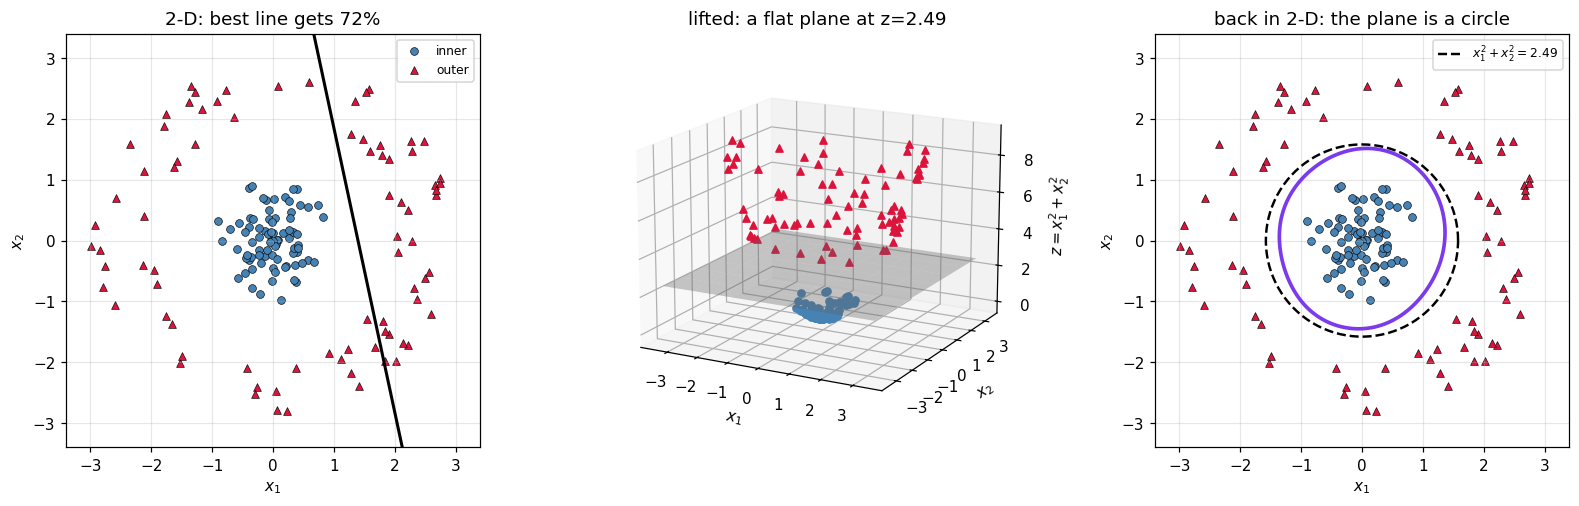

In [25]:
fig = plt.figure(figsize=(15, 4.6))

ax = fig.add_subplot(1, 3, 1)
ax.scatter(*X_in.T,  c="steelblue", s=26, edgecolor="k", linewidths=.4, label="inner")
ax.scatter(*X_out.T, c="crimson",  s=26, marker="^", edgecolor="k", linewidths=.4,
           label="outer")
gx, gy = np.meshgrid(np.linspace(-3.4, 3.4, 250), np.linspace(-3.4, 3.4, 250))
ax.contour(gx, gy, (lin_fail.decision_function(np.c_[gx.ravel(), gy.ravel()])
                    .reshape(gx.shape)), levels=[0], colors="k", linewidths=2)
ax.set(title=f"2-D: best line gets {acc_lin:.0%}", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.scatter(X_in[:,0],  X_in[:,1],  Z[yr==-1], c="steelblue", s=22, depthshade=False)
ax.scatter(X_out[:,0], X_out[:,1], Z[yr==1],  c="crimson", marker="^", s=22,
           depthshade=False)
pg1, pg2 = np.meshgrid(np.linspace(-3.4, 3.4, 8), np.linspace(-3.4, 3.4, 8))
ax.plot_surface(pg1, pg2, np.full_like(pg1, c_eff), alpha=.35, color="grey")
ax.set(xlabel="$x_1$", ylabel="$x_2$", zlabel="$z=x_1^2+x_2^2$",
       title=f"lifted: a flat plane at z={c_eff:.2f}")
ax.view_init(elev=16, azim=-62)

ax = fig.add_subplot(1, 3, 3)
ax.scatter(*X_in.T,  c="steelblue", s=26, edgecolor="k", linewidths=.4)
ax.scatter(*X_out.T, c="crimson",  s=26, marker="^", edgecolor="k", linewidths=.4)
ax.contour(gx, gy, (rbf_ring.decision_function(np.c_[gx.ravel(), gy.ravel()])
                    .reshape(gx.shape)), levels=[0], colors="#7c3aed", linewidths=2.4)
th = np.linspace(0, 2*np.pi, 200)
ax.plot(np.sqrt(c_eff)*np.cos(th), np.sqrt(c_eff)*np.sin(th), "k--", lw=1.6,
        label=f"$x_1^2+x_2^2={c_eff:.2f}$")
ax.set(title="back in 2-D: the plane is a circle", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.grid(alpha=.3)

plt.tight_layout(); plt.show()

---
# 11. Predicting Through the Kernel

Once kernelised, prediction never uses $\mathbf{w}$ &mdash; it may not even exist in finite
dimensions. Instead:

$$f(\mathbf{x}) = \sum_{i \in SV} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b,
\qquad \hat{y} = \operatorname{sign} f(\mathbf{x})$$

This is why a kernel SVM must keep its support vectors: they are the model.

In [26]:
rbf = SVC(kernel="rbf", C=1.0, gamma=0.5).fit(Pz, t2)
dc = rbf.dual_coef_[0]
svs = rbf.support_vectors_
b_r = float(rbf.intercept_[0])

xq = Pz[3]
print(f"classifying {ep_ids[3]} = {np.round(xq, 4)}  (true class {t2[3]})\n")
kv = np.exp(-0.5 * np.sum((svs - xq)**2, axis=1))

print(f"{'SV':>6}  {'alpha*y':>10}  {'K(sv, x)':>11}  {'product':>11}")
print("-" * 44)
for k, i in enumerate(rbf.support_):
    print(f"{ep_ids[i]:>6}  {dc[k]:>10.5f}  {kv[k]:>11.6f}  {dc[k]*kv[k]:>11.6f}")
print("-" * 44)
tot = float(dc @ kv)
print(f"{'sum':>6}  {'':>10}  {'':>11}  {tot:>11.6f}")
print(f"\nf(x) = {tot:.6f} + b({b_r:+.6f}) = {tot + b_r:+.6f}")
print(f"sklearn decision_function      = {rbf.decision_function(xq[None,:])[0]:+.6f}")
print(f"MATCH: {np.isclose(tot + b_r, rbf.decision_function(xq[None,:])[0])}")
print(f"\nprediction = sign({tot+b_r:+.4f}) -> class "
      f"{1 if tot+b_r > 0 else 0},  true {t2[3]}")

mine_all = np.array([1 if (float(np.exp(-0.5*np.sum((svs-Pz[i])**2,axis=1)) @ dc) + b_r) > 0
                     else 0 for i in range(n2)])
print(f"\nall {n2} predictions computed by hand MATCH sklearn: "
      f"{np.array_equal(mine_all, rbf.predict(Pz))}")

classifying ep03 = [-0.8269 -0.8518]  (true class 0)

    SV     alpha*y     K(sv, x)      product
--------------------------------------------
  ep02    -0.58915     0.757406    -0.446223
  ep05    -0.49117     0.958231    -0.470658
  ep08    -1.00000     0.843102    -0.843102
  ep09    -1.00000     0.370227    -0.370227
  ep12     1.00000     0.152669     0.152669
  ep13     0.48522     0.003394     0.001647
  ep17     0.59510     0.147128     0.087556
  ep18     1.00000     0.681131     0.681131
--------------------------------------------
   sum                             -1.207206

f(x) = -1.207206 + b(+0.076839) = -1.130367
sklearn decision_function      = -1.130367
MATCH: True

prediction = sign(-1.1304) -> class 0,  true 0

all 20 predictions computed by hand MATCH sklearn: True


---
# 12. Checking Against scikit-learn

In [27]:
print("linear SVM, dual solution")
print("-" * 56)
print(f"w from dual sum : {np.round(w_dual, 8)}")
print(f"w from sklearn  : {np.round(w_sv, 8)}")
print(f"MATCH: {np.allclose(w_dual, w_sv)}")

f_mine = Pz @ w_dual + b_sv
print(f"\ndecision_function MATCH: "
      f"{np.allclose(f_mine, lin.decision_function(Pz))}")
print(f"predictions MATCH      : "
      f"{np.array_equal((f_mine > 0).astype(int), lin.predict(Pz))}")

print(f"\n\nhinge-loss objective vs sklearn's own solution")
print("-" * 56)
for Cv in (0.1, 1.0, 10.0):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    obj_sk, _ = hinge_objective(m.coef_[0], float(m.intercept_[0]), Cv)
    rng_p = np.random.default_rng(0)
    better = 0
    for _ in range(4000):
        pert_w = m.coef_[0] + rng_p.normal(scale=.05, size=2)
        pert_b = float(m.intercept_[0]) + rng_p.normal(scale=.05)
        if hinge_objective(pert_w, pert_b, Cv)[0] < obj_sk - 1e-9:
            better += 1
    print(f"C = {Cv:>6}: objective {obj_sk:.6f}, "
          f"random perturbations that beat it: {better}/4000")
print("-" * 56)
print("\nNo nearby perturbation improves the objective, which is what we expect")
print("at the optimum of a convex problem.")

print(f"\n\nkernel matrix computed by hand vs sklearn")
print("-" * 56)
from sklearn.metrics.pairwise import rbf_kernel, polynomial_kernel
print(f"RBF  MATCH: {np.allclose(kernel_matrix(Pz,'rbf',gamma=0.5), rbf_kernel(Pz, gamma=0.5))}")
print(f"poly MATCH: {np.allclose(kernel_matrix(Pz,'poly',gamma=1.0,degree=3,coef0=1.0), polynomial_kernel(Pz, degree=3, gamma=1.0, coef0=1.0))}")

linear SVM, dual solution
--------------------------------------------------------
w from dual sum : [0.8873 0.8112]
w from sklearn  : [0.8873 0.8112]
MATCH: True

decision_function MATCH: True
predictions MATCH      : True


hinge-loss objective vs sklearn's own solution
--------------------------------------------------------
C =    0.1: objective 0.707809, random perturbations that beat it: 0/4000
C =    1.0: objective 3.733068, random perturbations that beat it: 0/4000
C =   10.0: objective 28.805766, random perturbations that beat it: 0/4000
--------------------------------------------------------

No nearby perturbation improves the objective, which is what we expect
at the optimum of a convex problem.


kernel matrix computed by hand vs sklearn
--------------------------------------------------------
RBF  MATCH: True
poly MATCH: True


---
# 13. Summary

| Concept | Formula |
|---|---|
| Margin | $2/\lVert\mathbf{w}\rVert$ |
| Primal | $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\max(0, 1-y_i f(\mathbf{x}_i))$ |
| Dual | $\sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_iy_j K(\mathbf{x}_i,\mathbf{x}_j)$ |
| Recover $\mathbf{w}$ | $\sum_i \alpha_i y_i \mathbf{x}_i$ |
| Predict | $\operatorname{sign}\big(\sum_{i\in SV}\alpha_i y_i K(\mathbf{x}_i,\mathbf{x}) + b\big)$ |
| Support vector | $\alpha_i > 0$, i.e. on or inside the margin |
| $C$ | large = narrow margin, few violations |
| $\gamma$ (RBF) | large = tight, local bubbles = overfitting |

**The one idea:** write the problem so the data appears only as inner products, and every
inner product becomes a free choice. That is the kernel trick, and it turns a linear
classifier into a family that includes infinite-dimensional feature spaces.

**The practical cost:** the dual is $O(n^2)$ to $O(n^3)$ in the number of samples, and the
kernel matrix is $n \times n$. SVMs are excellent up to tens of thousands of rows and
impractical at millions &mdash; which is precisely the range where the gradient-boosted trees
in this series take over.

**What is deliberately left out:** the KKT conditions and how $b$ is recovered from them,
the SMO algorithm that actually solves the dual, multi-class strategies (one-vs-one,
one-vs-rest), probability calibration via Platt scaling, and the $\nu$-SVM
parameterisation.